# Preprocesamiento terrestre iterativo desde los datos crudos

Este notebook toma **una decisión de preprocesamiento a la vez** y conserva la trazabilidad desde los archivos originales.

Principios de trabajo:

1. Los tres archivos entregados son la única fuente de datos terrestres.
2. El EDA inicial describe los datos sin eliminar, imputar ni corregir valores.
3. Cada transformación tiene una regla, una justificación y conteos antes/después.
4. `0 mm` se mantiene distinto de un dato faltante mientras no se demuestre que es un cero falso.
5. La fe de erratas fija el periodo **1981–2003** y la partición temporal **1981–1995 / 1996–2000 / 2001–2003**.
6. Los umbrales y criterios se justifican exclusivamente con entrenamiento. Validación y prueba solo reciben reglas ya congeladas.
7. La información satelital y fuentes externas no intervienen en este preprocesamiento terrestre.

**Estado del archivo:** notebook canónico de preprocesamiento terrestre. Las decisiones aprobadas se acumulan sin sobrescribir `datos_crudos`.


## 0. Preparación

La normalización de nombres y tipos permite analizar juntos los archivos, pero no cambia la precipitación. La columna `precipitacion_original_mm` conserva el valor recibido.


In [1]:
%matplotlib inline
from pathlib import Path
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

ROOT = Path.cwd()
if not (ROOT / 'P_1930_1979.xlsx').exists():
    ROOT = Path(r'E:\Proyecto_final_AnalíticaDeDatos')

FUENTES = [
    ROOT / 'P_1930_1979.xlsx',
    ROOT / 'P_1980_1990.csv',
    ROOT / 'P_1991_2003.csv',
]
FUENTES


## 1. Carga trazable de los archivos

Se exige que cada archivo contenga `STATION_ID`, `YEAR`, `MONTH`, `DAY` y `VALUE`. Se agrega el nombre del archivo y el número de fila de origen para poder rastrear cualquier hallazgo.


In [2]:
COLUMNAS_REQUERIDAS = {'STATION_ID', 'YEAR', 'MONTH', 'DAY', 'VALUE'}

def normalizar_id_estacion(serie):
    numerica = pd.to_numeric(serie, errors='coerce')
    return numerica.astype('Int64').astype('string')

def leer_fuente(ruta):
    if ruta.suffix.lower() == '.xlsx':
        original = pd.read_excel(ruta, sheet_name=0, engine='openpyxl')
    else:
        original = pd.read_csv(ruta, low_memory=False)

    original.columns = [str(c).strip().upper() for c in original.columns]
    faltantes = COLUMNAS_REQUERIDAS.difference(original.columns)
    if faltantes:
        raise ValueError(f'{ruta.name}: faltan columnas {sorted(faltantes)}')

    datos = original[['STATION_ID', 'YEAR', 'MONTH', 'DAY', 'VALUE']].copy()
    datos.columns = ['station_id', 'year', 'month', 'day', 'precipitacion_original_mm']
    datos.insert(0, 'archivo_origen', ruta.name)
    datos.insert(1, 'fila_origen', np.arange(2, len(datos) + 2, dtype=np.int64))

    datos['station_id'] = normalizar_id_estacion(datos['station_id'])
    for col in ['year', 'month', 'day', 'precipitacion_original_mm']:
        datos[col] = pd.to_numeric(datos[col], errors='coerce')
    datos[['year', 'month', 'day']] = datos[['year', 'month', 'day']].astype('Int64')
    datos['fecha'] = pd.to_datetime(
        dict(year=datos['year'], month=datos['month'], day=datos['day']),
        errors='coerce'
    )
    return datos

partes = [leer_fuente(ruta) for ruta in FUENTES]
datos_crudos = pd.concat(partes, ignore_index=True)
datos_crudos.insert(0, 'row_id', np.arange(len(datos_crudos), dtype=np.int64))

# La partición se crea inmediatamente después de cargar. Así, los diagnósticos
# que pueden influir en reglas usan solo entrenamiento.
ANIO_INICIO = 1981
ANIO_FIN = 2003
ORDEN_PARTICIONES = ['ENTRENAMIENTO', 'VALIDACION', 'PRUEBA']
datos_periodo = datos_crudos.loc[datos_crudos.year.between(ANIO_INICIO, ANIO_FIN)].copy()
datos_periodo['particion'] = np.select(
    [
        datos_periodo.year.between(1981, 1995),
        datos_periodo.year.between(1996, 2000),
        datos_periodo.year.between(2001, 2003),
    ],
    ORDEN_PARTICIONES,
    default='FUERA_DE_PARTICION'
)
if datos_periodo.particion.eq('FUERA_DE_PARTICION').any():
    raise ValueError('Existen registros del periodo oficial sin partición temporal.')
datos_eda_entrenamiento = datos_periodo.loc[
    datos_periodo.particion.eq('ENTRENAMIENTO')
].copy()

print(f'Registros crudos cargados: {len(datos_crudos):,}')
print(f'Registros del periodo oficial: {len(datos_periodo):,}')
print(f'Registros disponibles para decisiones de preprocesamiento: {len(datos_eda_entrenamiento):,}')
print(f'Archivos cargados: {datos_crudos.archivo_origen.nunique()}')


Registros crudos cargados: 2,992,694
Registros del periodo oficial: 1,930,611
Registros disponibles para decisiones de preprocesamiento: 1,348,410
Archivos cargados: 3


# EDA básico con separación temporal

El inventario de archivos y años describe todo lo recibido. En cambio, las distribuciones, extremos, cobertura y demás diagnósticos que pueden influir en decisiones se calculan únicamente con **entrenamiento, 1981–1995**.

Las palabras *posible*, *observado* o *preliminar* indican que todavía no se elimina ni se imputa ningún dato.


## 2. Inventario por archivo


In [3]:
inventario = (
    datos_crudos.groupby('archivo_origen', sort=False)
    .agg(
        registros=('row_id', 'size'),
        estaciones=('station_id', 'nunique'),
        anio_inicial=('year', 'min'),
        anio_final=('year', 'max'),
        valores_faltantes=('precipitacion_original_mm', lambda s: int(s.isna().sum())),
        ceros=('precipitacion_original_mm', lambda s: int(s.eq(0).sum())),
        negativos=('precipitacion_original_mm', lambda s: int(s.lt(0).sum())),
        maximo_mm=('precipitacion_original_mm', 'max'),
    )
    .reset_index()
)
inventario['porcentaje_ceros'] = 100 * inventario['ceros'] / inventario['registros']
display(inventario)


,archivo_origen,registros,estaciones,anio_inicial,anio_final,valores_faltantes,ceros,negativos,maximo_mm,porcentaje_ceros
0,P_1930_1979.xlsx,984226,264,1930,1979,0,559657,0,736.000,56.863
1,P_1980_1990.csv,997791,302,1980,1990,0,578166,0,"859,375.000",57.945
2,P_1991_2003.csv,1010677,284,1991,2003,0,597017,0,600.000,59.071


## 3. Estructura general y ejemplo de registros


In [4]:
pares_observados = datos_crudos[['station_id', 'year']].dropna().drop_duplicates()
resumen_estructura = pd.DataFrame({
    'metrica': [
        'registros', 'estaciones', 'años distintos', 'año inicial', 'año final',
        'pares estación-año observados', 'fechas no construibles',
        'valores de precipitación faltantes'
    ],
    'valor': [
        len(datos_crudos), datos_crudos.station_id.nunique(), datos_crudos.year.nunique(),
        datos_crudos.year.min(), datos_crudos.year.max(), len(pares_observados),
        int(datos_crudos.fecha.isna().sum()),
        int(datos_crudos.precipitacion_original_mm.isna().sum())
    ]
})
display(resumen_estructura)
display(pd.DataFrame({'tipo': datos_crudos.dtypes.astype(str)}))
display(datos_crudos.head(8))


,metrica,valor
0,registros,2992694
1,estaciones,344
2,años distintos,74
3,año inicial,1930
4,año final,2003
5,pares estación-año observados,8657
6,fechas no construibles,0
7,valores de precipitación faltantes,0


,tipo
row_id,int64
archivo_origen,str
fila_origen,int64
station_id,string
year,Int64
month,Int64
day,Int64
precipitacion_original_mm,float64
fecha,datetime64[us]


,row_id,archivo_origen,fila_origen,station_id,year,month,day,precipitacion_original_mm,fecha
0,0,P_1930_1979.xlsx,2,2610000101,1952,1,18,0.000,1952-01-18
1,1,P_1930_1979.xlsx,3,2610000101,1952,1,19,0.000,1952-01-19
2,2,P_1930_1979.xlsx,4,2610000101,1952,1,20,0.000,1952-01-20
3,3,P_1930_1979.xlsx,5,2610000101,1952,1,21,0.000,1952-01-21
4,4,P_1930_1979.xlsx,6,2610000101,1952,1,22,8.000,1952-01-22
5,5,P_1930_1979.xlsx,7,2610000101,1952,1,23,0.000,1952-01-23
6,6,P_1930_1979.xlsx,8,2610000101,1952,1,24,22.000,1952-01-24
7,7,P_1930_1979.xlsx,9,2610000101,1952,1,25,0.000,1952-01-25


## 4. Fechas, claves repetidas y valores básicos en entrenamiento

Una clave diaria se define como estación, año, mes y día. Se cuentan repeticiones únicamente en 1981–1995 para evitar que validación o prueba influyan en la definición posterior de reglas. Todavía no se consolida ninguna observación.


In [5]:
CLAVE_DIARIA = ['station_id', 'year', 'month', 'day']
datos_diagnostico = datos_eda_entrenamiento
clave_completa = datos_diagnostico[CLAVE_DIARIA].notna().all(axis=1)
duplicado_cualquiera = datos_diagnostico.loc[clave_completa].duplicated(CLAVE_DIARIA, keep=False)
duplicado_adicional = datos_diagnostico.loc[clave_completa].duplicated(CLAVE_DIARIA, keep='first')
filas_claves_repetidas = datos_diagnostico.loc[clave_completa].loc[duplicado_cualquiera]
if len(filas_claves_repetidas):
    valores_por_clave = filas_claves_repetidas.groupby(CLAVE_DIARIA, dropna=False)['precipitacion_original_mm'].nunique(dropna=False)
    claves_conflictivas = int(valores_por_clave.gt(1).sum())
else:
    claves_conflictivas = 0

p = datos_diagnostico.precipitacion_original_mm
diagnostico_basico = pd.DataFrame({
    'hallazgo_en_entrenamiento': [
        'claves incompletas', 'fechas no construibles', 'filas adicionales por clave repetida',
        'claves repetidas con valores diferentes', 'valores faltantes', 'valores negativos',
        'valores iguales a cero', 'valores positivos', 'valores mayores que 300 mm',
        'valores mayores que 1000 mm'
    ],
    'cantidad': [
        int((~clave_completa).sum()), int(datos_diagnostico.fecha.isna().sum()), int(duplicado_adicional.sum()),
        claves_conflictivas, int(p.isna().sum()), int(p.lt(0).sum()), int(p.eq(0).sum()),
        int(p.gt(0).sum()), int(p.gt(300).sum()), int(p.gt(1000).sum())
    ]
})
display(diagnostico_basico)


,hallazgo_en_entrenamiento,cantidad
0,claves incompletas,0
1,fechas no construibles,0
2,filas adicionales por clave repetida,0
3,claves repetidas con valores diferentes,0
4,valores faltantes,0
5,valores negativos,0
6,valores iguales a cero,784441
7,valores positivos,563969
8,valores mayores que 300 mm,47
9,valores mayores que 1000 mm,1


## 5. Distribución de la precipitación en entrenamiento

Los cuantiles se calculan únicamente con valores positivos de 1981–1995. Así, la gran cantidad de ceros no oculta la escala de los días lluviosos y los extremos de validación o prueba no participan en decisiones.


In [6]:
positivos = datos_eda_entrenamiento.loc[
    datos_eda_entrenamiento.precipitacion_original_mm.gt(0),
    'precipitacion_original_mm'
]
cuantiles = positivos.quantile([0, .25, .50, .75, .90, .95, .99, .995, .999, 1]).rename('precipitacion_mm').to_frame()
cuantiles.index.name = 'cuantil'
display(cuantiles)

mayores = datos_eda_entrenamiento.nlargest(15, 'precipitacion_original_mm')[
    ['archivo_origen', 'fila_origen', 'station_id', 'fecha', 'particion', 'precipitacion_original_mm']
]
display(Markdown('**Quince valores diarios más altos de entrenamiento, todavía sin decidir si son válidos:**'))
display(mayores)


,precipitacion_mm
cuantil,
0.000,0.100
0.250,3.000
0.500,8.000
0.750,18.000
0.900,33.000
0.950,46.000
0.990,84.000
0.995,103.000
0.999,149.000


**Quince valores diarios más altos de entrenamiento, todavía sin decidir si son válidos:**

,archivo_origen,fila_origen,station_id,fecha,particion,precipitacion_original_mm
1327944,P_1980_1990.csv,343720,2611600101,1984-01-10,ENTRENAMIENTO,"859,375.000"
1132102,P_1980_1990.csv,147878,5421200201,1981-10-31,ENTRENAMIENTO,943.000
1096577,P_1980_1990.csv,112353,5421200201,1981-05-31,ENTRENAMIENTO,896.000
1089428,P_1980_1990.csv,105204,5421200201,1981-04-30,ENTRENAMIENTO,851.000
1581214,P_1980_1990.csv,596990,5300000201,1986-09-30,ENTRENAMIENTO,838.000
1110722,P_1980_1990.csv,126498,5421200201,1981-07-31,ENTRENAMIENTO,750.000
1573505,P_1980_1990.csv,589281,5300000201,1986-08-31,ENTRENAMIENTO,732.000
1557568,P_1980_1990.csv,573344,5300000201,1986-06-30,ENTRENAMIENTO,681.000
1549833,P_1980_1990.csv,565609,5300000201,1986-05-31,ENTRENAMIENTO,630.000
1124960,P_1980_1990.csv,140736,5421200201,1981-09-30,ENTRENAMIENTO,592.000


## 6. Cobertura observada en entrenamiento

La cobertura preliminar es el porcentaje de fechas únicas con valor no faltante respecto a los 365 o 366 días esperados. Esta primera distribución se calcula solo para 1981–1995; todavía no se aplica un umbral.


In [7]:
observaciones_validas_para_conteo = datos_eda_entrenamiento.loc[
    datos_eda_entrenamiento.station_id.notna()
    & datos_eda_entrenamiento.fecha.notna()
    & datos_eda_entrenamiento.precipitacion_original_mm.notna(),
    ['station_id', 'year', 'fecha']
].drop_duplicates()

cobertura_preliminar = (
    observaciones_validas_para_conteo.groupby(['station_id', 'year'], as_index=False)
    .agg(dias_observados=('fecha', 'nunique'))
)
cobertura_preliminar['dias_esperados'] = cobertura_preliminar.year.map(
    lambda anio: 366 if calendar.isleap(int(anio)) else 365
)
cobertura_preliminar['cobertura_pct'] = (
    100 * cobertura_preliminar.dias_observados / cobertura_preliminar.dias_esperados
)

bandas = pd.cut(
    cobertura_preliminar.cobertura_pct,
    bins=[-np.inf, 50, 80, 90, 95, 99.999999, np.inf],
    labels=['<50%', '50-<80%', '80-<90%', '90-<95%', '95-<100%', '100%'],
    right=False
)
tabla_bandas = bandas.value_counts(sort=False).rename_axis('cobertura').reset_index(name='pares_entrenamiento')
display(tabla_bandas)
display(cobertura_preliminar.cobertura_pct.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).to_frame('cobertura_pct_entrenamiento'))


,cobertura,pares_entrenamiento
0,<50%,107
1,50-<80%,124
2,80-<90%,109
3,90-<95%,158
4,95-<100%,593
5,100%,2756


,cobertura_pct_entrenamiento
count,"3,847.000"
mean,95.977
std,13.585
min,0.822
10%,91.507
25%,99.726
50%,100.000
75%,100.000
90%,100.000
95%,100.000


## 7. Gráficas descriptivas

La disponibilidad anual se muestra como inventario. Los histogramas de cobertura y precipitación que pueden influir en decisiones utilizan solamente entrenamiento.


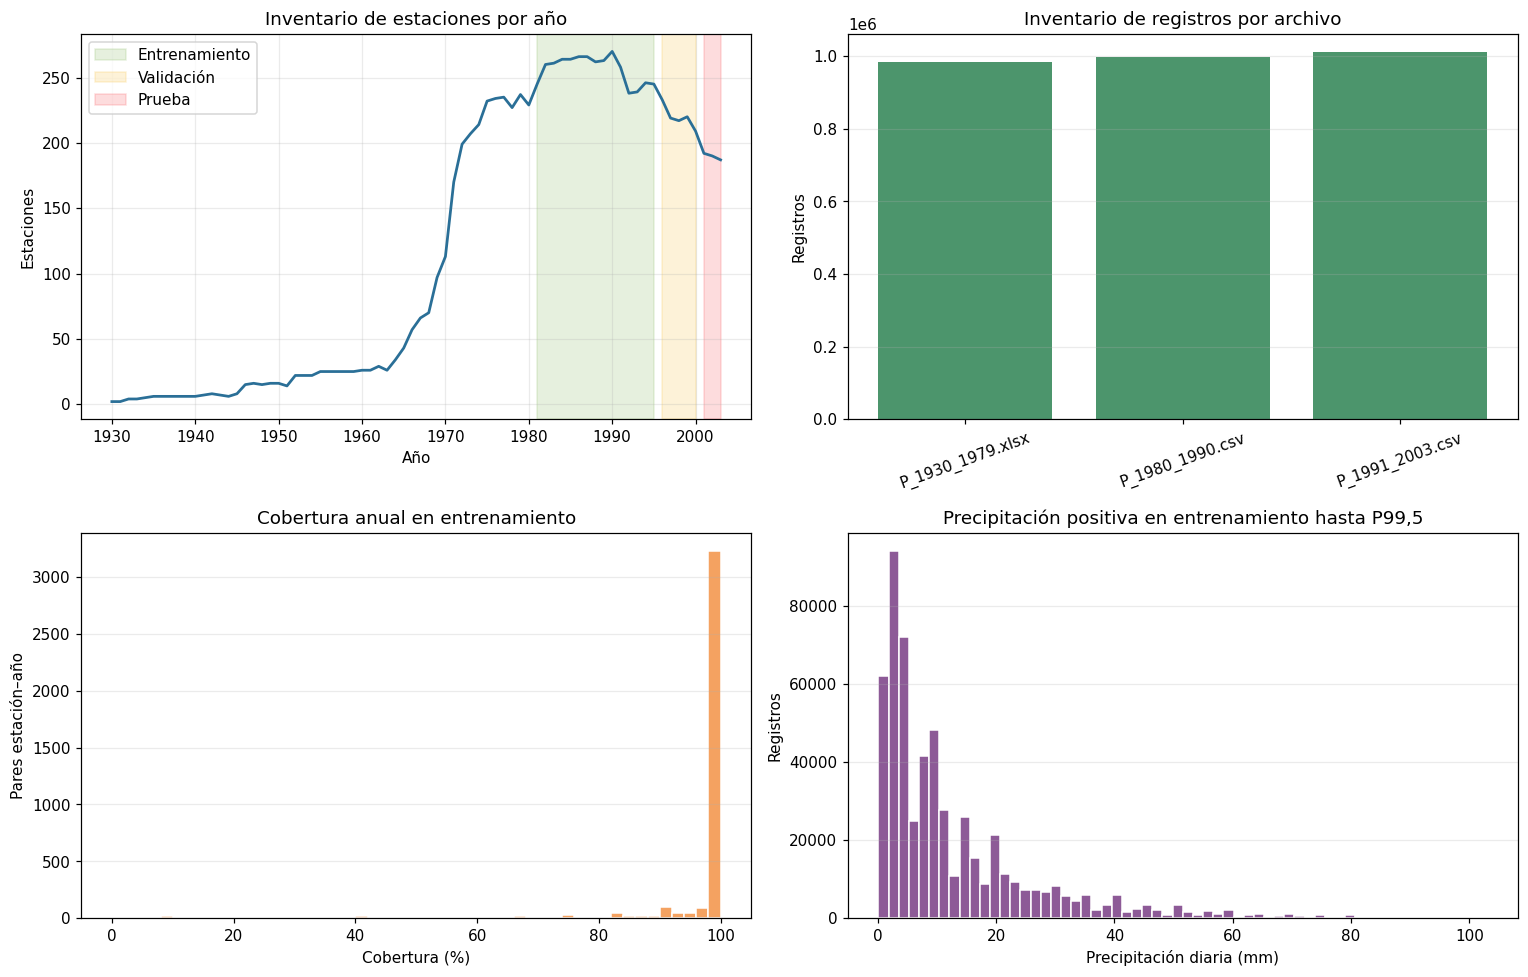

In [8]:
por_anio = (
    datos_crudos.dropna(subset=['year', 'station_id'])
    .groupby('year')
    .agg(estaciones=('station_id', 'nunique'), registros=('row_id', 'size'))
    .reset_index()
)
limite_histograma = positivos.quantile(.995)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].plot(por_anio.year, por_anio.estaciones, color='#2a6f97', linewidth=1.8)
axes[0, 0].axvspan(1981, 1995, color='#90be6d', alpha=.22, label='Entrenamiento')
axes[0, 0].axvspan(1996, 2000, color='#f9c74f', alpha=.22, label='Validación')
axes[0, 0].axvspan(2001, 2003, color='#f94144', alpha=.18, label='Prueba')
axes[0, 0].set(title='Inventario de estaciones por año', xlabel='Año', ylabel='Estaciones')
axes[0, 0].legend()
axes[0, 0].grid(alpha=.25)

axes[0, 1].bar(inventario.archivo_origen, inventario.registros, color='#4c956c')
axes[0, 1].set(title='Inventario de registros por archivo', ylabel='Registros')
axes[0, 1].tick_params(axis='x', rotation=20)
axes[0, 1].grid(axis='y', alpha=.25)

axes[1, 0].hist(cobertura_preliminar.cobertura_pct, bins=np.arange(0, 102, 2), color='#f4a261', edgecolor='white')
axes[1, 0].set(title='Cobertura anual en entrenamiento', xlabel='Cobertura (%)', ylabel='Pares estación–año')
axes[1, 0].grid(axis='y', alpha=.25)

axes[1, 1].hist(positivos[positivos.le(limite_histograma)], bins=60, color='#8d5a97', edgecolor='white')
axes[1, 1].set(title='Precipitación positiva en entrenamiento hasta P99,5', xlabel='Precipitación diaria (mm)', ylabel='Registros')
axes[1, 1].grid(axis='y', alpha=.25)

plt.tight_layout()
plt.show()


## 8. Hallazgos automáticos del EDA de entrenamiento


In [9]:
pares_observados = datos_crudos[['station_id', 'year']].dropna().drop_duplicates()
pares_entrenamiento_crudo = datos_eda_entrenamiento[['station_id', 'year']].dropna().drop_duplicates()
hallazgos = [
    f'El inventario completo contiene {len(datos_crudos):,} registros, {datos_crudos.station_id.nunique():,} estaciones y años entre {int(datos_crudos.year.min())} y {int(datos_crudos.year.max())}.',
    f'El periodo oficial contiene {len(datos_periodo):,} registros; entrenamiento aporta {len(datos_eda_entrenamiento):,} registros y {len(pares_entrenamiento_crudo):,} pares estación–año.',
    f'En entrenamiento hay {int(datos_eda_entrenamiento.fecha.isna().sum()):,} fechas no construibles y {int(datos_eda_entrenamiento.precipitacion_original_mm.isna().sum()):,} precipitaciones faltantes en origen.',
    f'En entrenamiento hay {int(p.eq(0).sum()):,} ceros ({100*p.eq(0).mean():.2f}%); todavía no se clasifican como reales o falsos.',
    f'En entrenamiento hay {int(p.lt(0).sum()):,} negativos, {int(p.gt(300).sum()):,} valores mayores que 300 mm y {int(p.gt(1000).sum()):,} mayores que 1000 mm.',
    f'En entrenamiento hay {int(duplicado_adicional.sum()):,} filas adicionales por claves repetidas y {claves_conflictivas:,} claves con valores diferentes.',
    f'La mediana de cobertura anual en entrenamiento es {cobertura_preliminar.cobertura_pct.median():.2f}%; todavía no decide qué años se aceptan.'
]
display(Markdown('\n'.join(f'- {texto}' for texto in hallazgos)))


- El inventario completo contiene 2,992,694 registros, 344 estaciones y años entre 1930 y 2003.
- El periodo oficial contiene 1,930,611 registros; entrenamiento aporta 1,348,410 registros y 3,847 pares estación–año.
- En entrenamiento hay 0 fechas no construibles y 0 precipitaciones faltantes en origen.
- En entrenamiento hay 784,441 ceros (58.18%); todavía no se clasifican como reales o falsos.
- En entrenamiento hay 0 negativos, 47 valores mayores que 300 mm y 1 mayores que 1000 mm.
- En entrenamiento hay 0 filas adicionales por claves repetidas y 0 claves con valores diferentes.
- La mediana de cobertura anual en entrenamiento es 100.00%; todavía no decide qué años se aceptan.

# Registro de decisiones

Cada fila debe cambiar de `PENDIENTE` a `APROBADA` solamente después de revisar la evidencia. Las reglas aprobadas se implementarán en una sección posterior sin sobrescribir `datos_crudos`.


In [10]:
registro_decisiones = pd.DataFrame([
    [1, 'Periodo y partición temporal', 'APROBADA', '1981-1995 entrenamiento; 1996-2000 validación; 2001-2003 prueba.'],
    [2, 'Fechas y claves incompletas', 'APROBADA', 'Las fechas imposibles no entran en las curvas; los faltantes se conservan como faltantes.'],
    [3, 'Duplicados diarios', 'APROBADA', 'Los duplicados exactos se consolidan; los conflictivos se invalidan sin promediar.'],
    [4, 'Error confirmado 859375 mm', 'APROBADA', 'Se conserva el original y se convierte solo la copia limpia en NaN.'],
    [5, 'Totales mensuales y digitación', 'APROBADA - ADAPTADA DE JACOBO', 'Reglas relativas; umbrales estimados solo con entrenamiento y congelados.'],
    [6, 'Años copiados entre estaciones', 'APROBADA - ADAPTADA DE JACOBO', 'Coincidencia diaria exacta en 365 días; se excluyen ambos pares sin asignar culpable.'],
    [7, 'Ceros falsos', 'APROBADA - ADAPTADA DE JACOBO', 'Rachas >=30 días y apoyo regional >=40%; se convierten en faltantes, nunca en lluvia satelital.'],
    [8, 'Cobertura y continuidad', 'APROBADA', '90% anual, hueco interior <=30 días y <=15 días faltantes en cada borde.'],
    [9, 'Tratamiento de faltantes', 'APROBADA PARA PREPROCESAMIENTO', 'No se imputa en esta fase; la construcción funcional ajustará con días observados.'],
    [10, 'Mínimo de años válidos', 'APROBADA', 'Cinco años válidos de entrenamiento por estación; luego se aplica la lista congelada.'],
    [11, 'Estaciones reservadas por el docente', 'PENDIENTE', 'Incorporar la lista oficial sin usarla para definir reglas ni ajustar el modelo.'],
], columns=['orden', 'decision', 'estado', 'objetivo'])
display(registro_decisiones)


,orden,decision,estado,objetivo
0,1,Periodo y partición temporal,APROBADA,1981-1995 entrenamiento; 1996-2000 validación;...
1,2,Fechas y claves incompletas,APROBADA,Las fechas imposibles no entran en las curvas;...
2,3,Duplicados diarios,APROBADA,Los duplicados exactos se consolidan; los conf...
3,4,Error confirmado 859375 mm,APROBADA,Se conserva el original y se convierte solo la...
4,5,Totales mensuales y digitación,APROBADA - ADAPTADA DE JACOBO,Reglas relativas; umbrales estimados solo con ...
5,6,Años copiados entre estaciones,APROBADA - ADAPTADA DE JACOBO,Coincidencia diaria exacta en 365 días; se exc...
6,7,Ceros falsos,APROBADA - ADAPTADA DE JACOBO,Rachas >=30 días y apoyo regional >=40%; se co...
7,8,Cobertura y continuidad,APROBADA,"90% anual, hueco interior <=30 días y <=15 día..."
8,9,Tratamiento de faltantes,APROBADA PARA PREPROCESAMIENTO,No se imputa en esta fase; la construcción fun...
9,10,Mínimo de años válidos,APROBADA,Cinco años válidos de entrenamiento por estaci...


# Decisión 1: periodo y partición temporal oficial

La fe de erratas establece el periodo **1981–2003** y la siguiente partición obligatoria:

- **Entrenamiento:** 1981–1995. Se usa para explorar distribuciones y decidir reglas de preprocesamiento.
- **Validación:** 1996–2000. Recibe las reglas congeladas; no modifica los umbrales.
- **Prueba:** 2001–2003. Se reserva para la evaluación final y no participa en decisiones.

El conjunto completo se conserva en `datos_crudos`. El filtro crea `datos_trabajo` y añade la columna `particion`. Esta separación ocurre antes de revisar cobertura, continuidad o mínimo de años.


**Cobertura de cada archivo entregado:**

,archivo_origen,desde,hasta,estaciones,pares_estacion_anio
0,P_1930_1979.xlsx,1930,1979,264,2914
1,P_1980_1990.csv,1980,1990,302,2850
2,P_1991_2003.csv,1991,2003,284,2893


**Partición temporal creada antes del preprocesamiento:**

,particion,desde,hasta,anios,registros,estaciones,pares_estacion_anio,uso_permitido
0,ENTRENAMIENTO,1981,1995,15,1348410,318,3847,Definir reglas y ajustar componentes del modelo
1,VALIDACION,1996,2000,5,381941,241,1098,Seleccionar hiperparámetros sin modificar reglas
2,PRUEBA,2001,2003,3,200260,194,569,Evaluación final una sola vez


**Efecto del filtro temporal oficial:**

,etapa,registros,estaciones,pares_estacion_anio,retenido_registros_pct,retenido_estaciones_pct,retenido_pares_estacion_anio_pct
0,Antes del filtro temporal (1930-2003),2992694,344,8657,100.0%,100.0%,100.0%
1,Después del filtro oficial (1981-2003),1930611,323,5514,64.5%,93.9%,63.7%


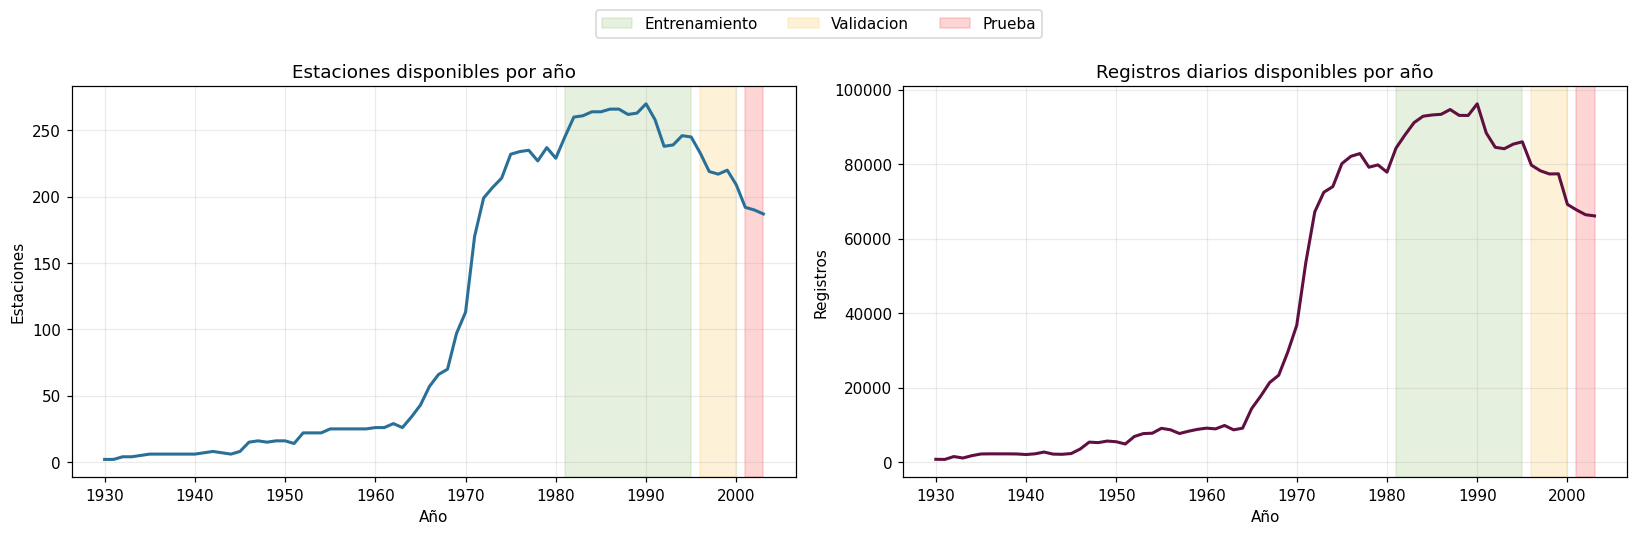

**Control de fuga:** a partir de esta celda, toda tabla que diga “sensibilidad” o “elección” se calcula solo con `ENTRENAMIENTO`. Los otros periodos se muestran únicamente después de congelar las reglas.

In [11]:
periodos_fuente = (
    datos_crudos.groupby('archivo_origen', sort=False)
    .agg(
        desde=('year', 'min'),
        hasta=('year', 'max'),
        estaciones=('station_id', 'nunique'),
    )
    .reset_index()
)
pares_por_archivo = (
    datos_crudos.dropna(subset=['station_id', 'year'])
    .drop_duplicates(['archivo_origen', 'station_id', 'year'])
    .groupby('archivo_origen').size()
)
periodos_fuente['pares_estacion_anio'] = periodos_fuente.archivo_origen.map(pares_por_archivo)

resumen_anual = por_anio.copy()

datos_trabajo = datos_periodo.copy()
if datos_trabajo.particion.eq('FUERA_DE_PARTICION').any():
    raise ValueError('Existen registros 1981-2003 sin partición temporal.')

pares_trabajo = (
    datos_trabajo[['station_id', 'year', 'particion']]
    .dropna(subset=['station_id', 'year'])
    .drop_duplicates()
)

resumen_particion = []
usos = {
    'ENTRENAMIENTO': 'Definir reglas y ajustar componentes del modelo',
    'VALIDACION': 'Seleccionar hiperparámetros sin modificar reglas',
    'PRUEBA': 'Evaluación final una sola vez',
}
for particion in ORDEN_PARTICIONES:
    d = datos_trabajo.loc[datos_trabajo.particion.eq(particion)]
    p = pares_trabajo.loc[pares_trabajo.particion.eq(particion)]
    resumen_particion.append({
        'particion': particion,
        'desde': int(d.year.min()),
        'hasta': int(d.year.max()),
        'anios': int(d.year.nunique()),
        'registros': int(len(d)),
        'estaciones': int(d.station_id.nunique()),
        'pares_estacion_anio': int(len(p)),
        'uso_permitido': usos[particion],
    })
resumen_particion = pd.DataFrame(resumen_particion)

trazabilidad_decision_1 = pd.DataFrame([
    {
        'etapa': 'Antes del filtro temporal (1930-2003)',
        'registros': len(datos_crudos),
        'estaciones': datos_crudos.station_id.nunique(),
        'pares_estacion_anio': len(pares_observados),
    },
    {
        'etapa': 'Después del filtro oficial (1981-2003)',
        'registros': len(datos_trabajo),
        'estaciones': datos_trabajo.station_id.nunique(),
        'pares_estacion_anio': len(pares_trabajo),
    },
])
for columna in ['registros', 'estaciones', 'pares_estacion_anio']:
    trazabilidad_decision_1[f'retenido_{columna}_pct'] = (
        100 * trazabilidad_decision_1[columna] / trazabilidad_decision_1.loc[0, columna]
    )

display(Markdown('**Cobertura de cada archivo entregado:**'))
display(periodos_fuente)
display(Markdown('**Partición temporal creada antes del preprocesamiento:**'))
display(resumen_particion)
display(Markdown('**Efecto del filtro temporal oficial:**'))
display(
    trazabilidad_decision_1.style.format({
        'retenido_registros_pct': '{:.1f}%',
        'retenido_estaciones_pct': '{:.1f}%',
        'retenido_pares_estacion_anio_pct': '{:.1f}%',
    })
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharex=True)
colores = {'ENTRENAMIENTO': '#90be6d', 'VALIDACION': '#f9c74f', 'PRUEBA': '#f94144'}
limites = {'ENTRENAMIENTO': (1981, 1995), 'VALIDACION': (1996, 2000), 'PRUEBA': (2001, 2003)}
for ax in axes:
    for nombre in ORDEN_PARTICIONES:
        inicio, fin = limites[nombre]
        ax.axvspan(inicio, fin, color=colores[nombre], alpha=.22, label=nombre.capitalize())

axes[0].plot(resumen_anual.year, resumen_anual.estaciones, color='#2a6f97', linewidth=2)
axes[0].set(title='Estaciones disponibles por año', xlabel='Año', ylabel='Estaciones')
axes[0].grid(alpha=.25)

axes[1].plot(resumen_anual.year, resumen_anual.registros, color='#5f0f40', linewidth=2)
axes[1].set(title='Registros diarios disponibles por año', xlabel='Año', ylabel='Registros')
axes[1].grid(alpha=.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[:3], labels[:3], loc='upper center', ncol=3, bbox_to_anchor=(.5, 1.02))
plt.tight_layout(rect=[0, 0, 1, .94])
plt.show()

display(Markdown(
    '**Control de fuga:** a partir de esta celda, toda tabla que diga “sensibilidad” o “elección” se calcula '
    'solo con `ENTRENAMIENTO`. Los otros periodos se muestran únicamente después de congelar las reglas.'
))


# Decisión 2: convertir el error de 859.375 mm en faltante

El registro de `859375 mm` pertenece a 1984, por tanto está dentro de entrenamiento. Se conserva en `precipitacion_original_mm` y se convierte en `NaN` únicamente en `precipitacion_limpia_mm`. No se convierte en cero porque un error no demuestra ausencia de lluvia.

La evidencia cuantitativa se calcula solamente con 1981–1995. La regla no consulta validación ni prueba.


In [12]:
datos_trabajo['precipitacion_limpia_mm'] = datos_trabajo['precipitacion_original_mm'].copy()
datos_trabajo['error_digitacion_859375'] = (
    datos_trabajo.station_id.eq('2611600101')
    & datos_trabajo.fecha.eq(pd.Timestamp('1984-01-10'))
    & datos_trabajo.precipitacion_original_mm.eq(859375)
)
datos_trabajo.loc[datos_trabajo.error_digitacion_859375, 'precipitacion_limpia_mm'] = np.nan

resultado_decision_2 = datos_trabajo.loc[
    datos_trabajo.error_digitacion_859375,
    ['archivo_origen', 'fila_origen', 'station_id', 'fecha', 'particion',
     'precipitacion_original_mm', 'precipitacion_limpia_mm']
]

valor_error = 859375.0
mascara_entrenamiento = datos_trabajo.particion.eq('ENTRENAMIENTO')
valores_sin_error = datos_trabajo.loc[
    mascara_entrenamiento & ~datos_trabajo.error_digitacion_859375,
    'precipitacion_original_mm'
].dropna()
positivos_sin_error = valores_sin_error[valores_sin_error.gt(0)]
maximo_sin_error = float(valores_sin_error.max())
evidencia_error = pd.DataFrame([
    {'indicador': 'Valor candidato', 'valor_mm': valor_error, 'interpretacion': 'Registro de entrenamiento que se evalúa'},
    {'indicador': 'Máximo restante de entrenamiento', 'valor_mm': maximo_sin_error, 'interpretacion': 'Mayor referencia 1981-1995 sin el candidato'},
    {'indicador': 'Percentil 99,9 positivo de entrenamiento', 'valor_mm': positivos_sin_error.quantile(.999), 'interpretacion': 'Extremo habitual en entrenamiento'},
    {'indicador': 'Razón candidato / máximo restante', 'valor_mm': valor_error / maximo_sin_error, 'interpretacion': 'Separación respecto al segundo extremo'},
    {'indicador': 'Registros modificados', 'valor_mm': int(datos_trabajo.error_digitacion_859375.sum()), 'interpretacion': 'Alcance exacto de la corrección'},
])

display(Markdown('**Registro afectado y trazabilidad del cambio:**'))
display(resultado_decision_2)
display(Markdown('**Evidencia obtenida exclusivamente de entrenamiento:**'))
display(evidencia_error.style.format({'valor_mm': '{:,.3f}'}))
display(Markdown(
    f'**Decisión:** se modifica solo 1 registro en la columna limpia. El candidato es '
    f'**{valor_error / maximo_sin_error:,.1f} veces** el máximo restante de entrenamiento. '
    'No se define una regla general que elimine lluvias extremas plausibles.'
))


**Registro afectado y trazabilidad del cambio:**

,archivo_origen,fila_origen,station_id,fecha,particion,precipitacion_original_mm,precipitacion_limpia_mm
1327944,P_1980_1990.csv,343720,2611600101,1984-01-10,ENTRENAMIENTO,"859,375.000",NaN


**Evidencia obtenida exclusivamente de entrenamiento:**

,indicador,valor_mm,interpretacion
0,Valor candidato,"859,375.000",Registro de entrenamiento que se evalúa
1,Máximo restante de entrenamiento,943.000,Mayor referencia 1981-1995 sin el candidato
2,"Percentil 99,9 positivo de entrenamiento",148.033,Extremo habitual en entrenamiento
3,Razón candidato / máximo restante,911.320,Separación respecto al segundo extremo
4,Registros modificados,1.000,Alcance exacto de la corrección


**Decisión:** se modifica solo 1 registro en la columna limpia. El candidato es **911.3 veces** el máximo restante de entrenamiento. No se define una regla general que elimine lluvias extremas plausibles.

# Decisión 3: adaptar los controles de totales mensuales y digitación de Jacobo

Se reproducen las ideas de la rama de Jacobo, pero se corrige la fuga de información:

- las distribuciones y percentiles se estiman únicamente con **entrenamiento (1981–1995)**;
- los umbrales elegidos se congelan antes de mirar validación y prueba;
- cada cambio afecta solo `precipitacion_limpia_mm`; el valor original y una bandera quedan disponibles;
- las tablas de sensibilidad muestran el costo de cada alternativa en entrenamiento.

Se aplican cuatro controles en orden: mes con un único registro, posible total mensual rodeado de ceros, mes con repetición extrema y error aislado de digitación. No se usa un límite absoluto general que elimine toda lluvia alta.


In [13]:
CLAVE_MES = ['station_id', 'year', 'month', 'particion']
MASCARA_TRAIN = datos_trabajo.particion.eq('ENTRENAMIENTO')

def claves_en_tabla(datos, columnas, tabla_claves):
    if tabla_claves.empty:
        return pd.Series(False, index=datos.index)
    izquierda = pd.MultiIndex.from_frame(datos[columnas])
    derecha = pd.MultiIndex.from_frame(tabla_claves[columnas].drop_duplicates())
    return pd.Series(izquierda.isin(derecha), index=datos.index)

def resumen_estado(nombre):
    valido = datos_trabajo.precipitacion_limpia_mm.notna()
    filas = []
    for particion in ORDEN_PARTICIONES + ['TOTAL']:
        mascara = valido if particion == 'TOTAL' else valido & datos_trabajo.particion.eq(particion)
        pares = datos_trabajo.loc[mascara, ['station_id', 'year']].drop_duplicates()
        filas.append({
            'etapa': nombre,
            'particion': particion,
            'registros_validos': int(mascara.sum()),
            'estaciones': int(datos_trabajo.loc[mascara, 'station_id'].nunique()),
            'pares_estacion_anio_con_dato': int(len(pares)),
        })
    return filas

traza_calidad = []
traza_calidad.extend(resumen_estado('00 después del error confirmado 859375'))

# 3A. Mes con un solo registro observado: no describe una curva mensual y se invalida.
resumen_mes = (
    datos_trabajo.groupby(CLAVE_MES, observed=True, dropna=False)
    .agg(registros_mes=('precipitacion_limpia_mm', 'count'))
    .reset_index()
)
meses_unico_registro = resumen_mes.loc[resumen_mes.registros_mes.eq(1), CLAVE_MES].copy()
datos_trabajo['mes_unico_registro'] = claves_en_tabla(datos_trabajo, CLAVE_MES, meses_unico_registro)
datos_trabajo.loc[datos_trabajo.mes_unico_registro, 'precipitacion_limpia_mm'] = np.nan
traza_calidad.extend(resumen_estado('01 mes con un único registro -> NaN'))

# 3B. Posible total mensual cargado en un día y ceros el resto del mes.
# La referencia climática es la mediana del total mensual para la misma estación y mes calendario,
# estimada exclusivamente en entrenamiento después del paso anterior.
def diagnostico_mensual_actual():
    d = datos_trabajo.assign(
        positivo=datos_trabajo.precipitacion_limpia_mm.gt(0),
    )
    return (
        d.groupby(CLAVE_MES, observed=True, dropna=False)
        .agg(
            registros_validos=('precipitacion_limpia_mm', 'count'),
            dias_positivos=('positivo', 'sum'),
            total_mes=('precipitacion_limpia_mm', 'sum'),
            maximo_dia=('precipitacion_limpia_mm', 'max'),
        )
        .reset_index()
    )

resumen_mes = diagnostico_mensual_actual()
medianas_train = (
    resumen_mes.loc[resumen_mes.particion.eq('ENTRENAMIENTO') & resumen_mes.registros_validos.ge(20)]
    .groupby(['station_id', 'month'], observed=True)['total_mes']
    .median()
    .rename('mediana_total_train')
    .reset_index()
)
resumen_mes = resumen_mes.merge(medianas_train, on=['station_id', 'month'], how='left')

sensibilidad_total_mensual = []
for min_registros in [20, 25, 28]:
    for fraccion in [0.25, 0.50, 0.75]:
        umbral = np.maximum(50.0, fraccion * resumen_mes.mediana_total_train)
        seleccion = (
            resumen_mes.particion.eq('ENTRENAMIENTO')
            & resumen_mes.registros_validos.ge(min_registros)
            & resumen_mes.dias_positivos.eq(1)
            & resumen_mes.maximo_dia.ge(umbral)
        )
        sensibilidad_total_mensual.append({
            'min_registros_mes': min_registros,
            'fraccion_mediana_historica': fraccion,
            'meses_marcados_train': int(seleccion.sum()),
            'estaciones_train': int(resumen_mes.loc[seleccion, 'station_id'].nunique()),
            'pares_train': int(resumen_mes.loc[seleccion, ['station_id', 'year']].drop_duplicates().shape[0]),
            'seleccionado': min_registros == 25 and np.isclose(fraccion, .50),
        })
sensibilidad_total_mensual = pd.DataFrame(sensibilidad_total_mensual)

MIN_REGISTROS_TOTAL = 25
FRACCION_MEDIANA_TOTAL = .50
umbral_total = np.maximum(50.0, FRACCION_MEDIANA_TOTAL * resumen_mes.mediana_total_train)
mascara_total = (
    resumen_mes.registros_validos.ge(MIN_REGISTROS_TOTAL)
    & resumen_mes.dias_positivos.eq(1)
    & resumen_mes.maximo_dia.ge(umbral_total)
)
meses_total_mensual = resumen_mes.loc[mascara_total, CLAVE_MES + [
    'registros_validos', 'maximo_dia', 'total_mes', 'mediana_total_train'
]].copy()
datos_trabajo['posible_total_mensual'] = claves_en_tabla(datos_trabajo, CLAVE_MES, meses_total_mensual)
datos_trabajo.loc[datos_trabajo.posible_total_mensual, 'precipitacion_limpia_mm'] = np.nan
traza_calidad.extend(resumen_estado('02 posible total mensual -> mes a NaN'))

# 3C. Mes con repetición anómala de valores extremos relativos a la estación.
# El p99 se aprende con positivos de entrenamiento ya depurados en 3A y 3B.
p99_train = (
    datos_trabajo.loc[
        MASCARA_TRAIN & datos_trabajo.precipitacion_limpia_mm.gt(0),
        ['station_id', 'precipitacion_limpia_mm']
    ]
    .groupby('station_id')['precipitacion_limpia_mm'].quantile(.99)
    .rename('p99_positivo_train')
)
datos_trabajo['p99_positivo_train'] = datos_trabajo.station_id.map(p99_train)

sensibilidad_mes_extremo = []
for multiplicador in [2.5, 3.0, 3.5, 4.0]:
    supera = datos_trabajo.precipitacion_limpia_mm.gt(
        multiplicador * datos_trabajo.p99_positivo_train
    )
    conteo = supera.groupby([
        datos_trabajo.station_id, datos_trabajo.year, datos_trabajo.month
    ]).transform('sum')
    for minimo_dias in [3, 5, 7]:
        filas = MASCARA_TRAIN & conteo.ge(minimo_dias)
        meses = datos_trabajo.loc[filas, ['station_id', 'year', 'month']].drop_duplicates()
        sensibilidad_mes_extremo.append({
            'multiplicador_p99_train': multiplicador,
            'min_dias_extremos_mes': minimo_dias,
            'meses_marcados_train': int(len(meses)),
            'estaciones_train': int(meses.station_id.nunique()),
            'seleccionado': np.isclose(multiplicador, 3.0) and minimo_dias == 5,
        })
sensibilidad_mes_extremo = pd.DataFrame(sensibilidad_mes_extremo)

supera_3p99 = datos_trabajo.precipitacion_limpia_mm.gt(3.0 * datos_trabajo.p99_positivo_train)
conteo_3p99_mes = supera_3p99.groupby([
    datos_trabajo.station_id, datos_trabajo.year, datos_trabajo.month
]).transform('sum')
meses_extremos = datos_trabajo.loc[
    conteo_3p99_mes.ge(5), CLAVE_MES
].drop_duplicates()
datos_trabajo['mes_anomalo_p99'] = claves_en_tabla(datos_trabajo, CLAVE_MES, meses_extremos)
datos_trabajo.loc[datos_trabajo.mes_anomalo_p99, 'precipitacion_limpia_mm'] = np.nan
traza_calidad.extend(resumen_estado('03 mes con >=5 días sobre 3*p99 train -> NaN'))

# 3D. Extremo aislado: regla relativa de Jacobo, con p99 congelado de entrenamiento.
sensibilidad_digitacion_relativa = []
for multiplicador in [3.0, 4.0, 5.0]:
    for piso_mm in [100, 150, 200]:
        seleccion = (
            MASCARA_TRAIN
            & datos_trabajo.precipitacion_limpia_mm.gt(piso_mm)
            & datos_trabajo.precipitacion_limpia_mm.gt(multiplicador * datos_trabajo.p99_positivo_train)
        )
        sensibilidad_digitacion_relativa.append({
            'multiplicador_p99_train': multiplicador,
            'piso_mm': piso_mm,
            'dias_marcados_train': int(seleccion.sum()),
            'estaciones_train': int(datos_trabajo.loc[seleccion, 'station_id'].nunique()),
            'pares_train': int(datos_trabajo.loc[seleccion, ['station_id', 'year']].drop_duplicates().shape[0]),
            'seleccionado': np.isclose(multiplicador, 4.0) and piso_mm == 150,
        })
sensibilidad_digitacion_relativa = pd.DataFrame(sensibilidad_digitacion_relativa)

datos_trabajo['error_digitacion_relativo'] = (
    datos_trabajo.precipitacion_limpia_mm.gt(150)
    & datos_trabajo.precipitacion_limpia_mm.gt(4.0 * datos_trabajo.p99_positivo_train)
)
datos_trabajo.loc[datos_trabajo.error_digitacion_relativo, 'precipitacion_limpia_mm'] = np.nan
traza_calidad.extend(resumen_estado('04 extremo aislado >150 y >4*p99 train -> NaN'))

def resaltar_seleccion(fila):
    color = 'background-color: #d9ead3; font-weight: bold' if bool(fila['seleccionado']) else ''
    return [color] * len(fila)

display(Markdown('**Sensibilidad del posible total mensual (solo entrenamiento):**'))
display(sensibilidad_total_mensual.style.apply(resaltar_seleccion, axis=1))
display(Markdown('**Sensibilidad del mes con repetición extrema (solo entrenamiento):**'))
display(sensibilidad_mes_extremo.style.apply(resaltar_seleccion, axis=1))
display(Markdown('**Sensibilidad del extremo aislado (solo entrenamiento):**'))
display(sensibilidad_digitacion_relativa.style.apply(resaltar_seleccion, axis=1))

impacto_totales = pd.concat([
    meses_unico_registro.assign(regla='Mes con un único registro'),
    meses_total_mensual[CLAVE_MES].assign(regla='Posible total mensual'),
    meses_extremos.assign(regla='Mes con repetición extrema'),
], ignore_index=True)
resumen_impacto_totales = (
    impacto_totales.groupby(['regla', 'particion'], observed=True)
    .agg(meses=('month', 'size'), estaciones=('station_id', 'nunique'))
    .reset_index()
)
resumen_dias_digitacion = (
    datos_trabajo.loc[datos_trabajo.error_digitacion_relativo]
    .groupby('particion', observed=True)
    .agg(dias=('row_id', 'size'), estaciones=('station_id', 'nunique'))
    .reset_index()
)
display(Markdown('**Aplicación congelada a cada partición:**'))
display(resumen_impacto_totales)
display(Markdown('**Días aislados invalidados por la regla relativa:**'))
display(resumen_dias_digitacion)
display(Markdown(
    '**Decisión:** se adopta la estructura de Jacobo, pero las referencias p99 y medianas provienen solo de entrenamiento. '
    'Las lluvias altas que no cumplen estas condiciones se conservan.'
))


**Sensibilidad del posible total mensual (solo entrenamiento):**

,min_registros_mes,fraccion_mediana_historica,meses_marcados_train,estaciones_train,pares_train,seleccionado
0,20,0.250000,13,12,13,False
1,20,0.500000,8,8,8,False
2,20,0.750000,6,6,6,False
3,25,0.250000,13,12,13,False
4,25,0.500000,8,8,8,True
5,25,0.750000,6,6,6,False
6,28,0.250000,12,11,12,False
7,28,0.500000,8,8,8,False
8,28,0.750000,6,6,6,False


**Sensibilidad del mes con repetición extrema (solo entrenamiento):**

,multiplicador_p99_train,min_dias_extremos_mes,meses_marcados_train,estaciones_train,seleccionado
0,2.500000,3,0,0,False
1,2.500000,5,0,0,False
2,2.500000,7,0,0,False
3,3.000000,3,0,0,False
4,3.000000,5,0,0,True
5,3.000000,7,0,0,False
6,3.500000,3,0,0,False
7,3.500000,5,0,0,False
8,3.500000,7,0,0,False
9,4.000000,3,0,0,False


**Sensibilidad del extremo aislado (solo entrenamiento):**

,multiplicador_p99_train,piso_mm,dias_marcados_train,estaciones_train,pares_train,seleccionado
0,3.000000,100,10,10,10,False
1,3.000000,150,7,7,7,False
2,3.000000,200,6,6,6,False
3,4.000000,100,3,3,3,False
4,4.000000,150,3,3,3,True
5,4.000000,200,3,3,3,False
6,5.000000,100,2,2,2,False
7,5.000000,150,2,2,2,False
8,5.000000,200,2,2,2,False


**Aplicación congelada a cada partición:**

,regla,particion,meses,estaciones
0,Mes con un único registro,ENTRENAMIENTO,54,15
1,Mes con un único registro,VALIDACION,3,3
2,Posible total mensual,ENTRENAMIENTO,8,8
3,Posible total mensual,PRUEBA,1,1
4,Posible total mensual,VALIDACION,2,2


**Días aislados invalidados por la regla relativa:**

,particion,dias,estaciones
0,ENTRENAMIENTO,3,3
1,PRUEBA,1,1
2,VALIDACION,1,1


**Decisión:** se adopta la estructura de Jacobo, pero las referencias p99 y medianas provienen solo de entrenamiento. Las lluvias altas que no cumplen estas condiciones se conservan.

# Decisión 4: años copiados y posibles ceros falsos

**Años copiados.** Se comparan los 365 valores diarios de cada año, excluyendo el 29 de febrero para usar el mismo dominio anual. Solo una coincidencia exacta y completa entre estaciones distintas activa la regla. Como no puede saberse cuál estación es la original, ambos pares estación–año pasan a faltante.

**Ceros falsos.** Se adapta la regla de Jacobo: una racha de al menos 30 ceros consecutivos se invalida cuando, durante esa racha, al menos 40% de las otras estaciones observadas de la misma macrozona registran lluvia en promedio. El 40% se presenta junto con una tabla de sensibilidad calculada solo en entrenamiento. Es una regla agresiva: no reemplaza el cero por lluvia regional ni satelital; lo convierte en faltante y luego vuelve a evaluar cobertura.


In [ ]:
import hashlib

# 4A. Años diarios copiados exactamente entre estaciones.
base_copias = datos_trabajo.loc[
    datos_trabajo.fecha.notna()
    & datos_trabajo.station_id.notna()
    & ~((datos_trabajo.fecha.dt.month == 2) & (datos_trabajo.fecha.dt.day == 29)),
    ['station_id', 'year', 'particion', 'fecha', 'precipitacion_original_mm']
].drop_duplicates(['station_id', 'year', 'fecha'], keep=False)

firmas = []
vectores = {}
for (estacion, anio, particion), grupo in base_copias.groupby(
    ['station_id', 'year', 'particion'], observed=True
):
    grupo = grupo.sort_values('fecha')
    if len(grupo) != 365 or grupo.precipitacion_original_mm.isna().any():
        continue
    valores = grupo.precipitacion_original_mm.to_numpy(dtype='<f8')
    firma = hashlib.sha256(valores.tobytes()).hexdigest()
    firmas.append({
        'station_id': estacion, 'year': int(anio), 'particion': particion,
        'firma': firma,
    })
    vectores[(estacion, int(anio))] = valores

firmas = pd.DataFrame(firmas)
grupos_copia = []
if not firmas.empty:
    for (anio, particion, firma), grupo in firmas.groupby(['year', 'particion', 'firma'], observed=True):
        estaciones = sorted(grupo.station_id.unique().tolist())
        if len(estaciones) < 2:
            continue
        referencia = vectores[(estaciones[0], int(anio))]
        iguales = [e for e in estaciones if np.array_equal(vectores[(e, int(anio))], referencia)]
        if len(iguales) >= 2:
            grupos_copia.append({
                'year': int(anio), 'particion': particion,
                'estaciones': ', '.join(iguales), 'n_estaciones': len(iguales),
                'firma_corta': firma[:12],
            })
grupos_copia = pd.DataFrame(grupos_copia)

pares_copiados = []
for fila in grupos_copia.itertuples(index=False):
    for estacion in fila.estaciones.split(', '):
        pares_copiados.append({
            'station_id': estacion, 'year': fila.year, 'particion': fila.particion
        })
pares_copiados = pd.DataFrame(pares_copiados, columns=['station_id', 'year', 'particion']).drop_duplicates()
datos_trabajo['anio_copiado'] = claves_en_tabla(
    datos_trabajo, ['station_id', 'year', 'particion'], pares_copiados
)
datos_trabajo.loc[datos_trabajo.anio_copiado, 'precipitacion_limpia_mm'] = np.nan
traza_calidad.extend(resumen_estado('05 año copiado exacto -> par a NaN'))

display(Markdown('**Grupos de años copiados encontrados por coincidencia exacta:**'))
display(grupos_copia if not grupos_copia.empty else pd.DataFrame({'resultado': ['No se detectaron grupos']}))
display(Markdown('**Pares afectados por partición:**'))
display(
    pares_copiados.groupby('particion').size().rename('pares').reset_index()
    if not pares_copiados.empty else pd.DataFrame({'resultado': ['Ningún par afectado']})
)

# 4B. Ceros falsos: misma aproximación regional de Jacobo, sin usar satélite.
datos_trabajo['macrozona'] = np.where(
    datos_trabajo.station_id.str.startswith('26', na=False), 'CAUCA', 'PACIFICO'
)
validos = datos_trabajo.precipitacion_limpia_mm.notna() & datos_trabajo.fecha.notna()
estado_diario_region = (
    datos_trabajo.loc[validos]
    .assign(lluvia=lambda x: x.precipitacion_limpia_mm.gt(0).astype(int))
    .groupby(['fecha', 'macrozona'], observed=True)
    .agg(estaciones_observadas=('station_id', 'nunique'), estaciones_con_lluvia=('lluvia', 'sum'))
    .reset_index()
)
ceros = datos_trabajo.loc[
    validos & datos_trabajo.precipitacion_limpia_mm.eq(0),
    ['row_id', 'station_id', 'year', 'particion', 'fecha', 'macrozona']
].merge(estado_diario_region, on=['fecha', 'macrozona'], how='left')
ceros['proporcion_otras_con_lluvia'] = (
    ceros.estaciones_con_lluvia / (ceros.estaciones_observadas - 1).replace(0, np.nan)
)

rachas = []
for (estacion, anio, particion, macrozona), grupo in ceros.groupby(
    ['station_id', 'year', 'particion', 'macrozona'], observed=True
):
    grupo = grupo.sort_values('fecha').copy()
    grupo['grupo_racha'] = grupo.fecha.diff().dt.days.ne(1).cumsum()
    for _, racha in grupo.groupby('grupo_racha'):
        if len(racha) < 30:
            continue
        rachas.append({
            'station_id': estacion, 'year': int(anio), 'particion': particion,
            'macrozona': macrozona, 'inicio': racha.fecha.min(), 'fin': racha.fecha.max(),
            'longitud_dias': int(len(racha)),
            'proporcion_regional_lluvia': float(racha.proporcion_otras_con_lluvia.mean()),
        })
rachas_cero = pd.DataFrame(rachas)

sensibilidad_ceros = []
for umbral in [0.20, 0.30, 0.40, 0.50, 0.60]:
    seleccion = (
        rachas_cero.particion.eq('ENTRENAMIENTO')
        & rachas_cero.proporcion_regional_lluvia.ge(umbral)
    ) if not rachas_cero.empty else pd.Series(dtype=bool)
    elegidas = rachas_cero.loc[seleccion] if not rachas_cero.empty else rachas_cero
    sensibilidad_ceros.append({
        'umbral_proporcion_regional': umbral,
        'rachas_marcadas_train': int(len(elegidas)),
        'dias_cero_marcados_train': int(elegidas.longitud_dias.sum()) if len(elegidas) else 0,
        'estaciones_train': int(elegidas.station_id.nunique()) if len(elegidas) else 0,
        'pares_train': int(elegidas[['station_id', 'year']].drop_duplicates().shape[0]) if len(elegidas) else 0,
        'seleccionado': np.isclose(umbral, .40),
    })
sensibilidad_ceros = pd.DataFrame(sensibilidad_ceros)
sensibilidad_ceros['dias_recuperados_vs_umbral_anterior'] = (
    sensibilidad_ceros.dias_cero_marcados_train.shift(1)
    - sensibilidad_ceros.dias_cero_marcados_train
).fillna(0).astype(int)

UMBRAL_CERO_REGIONAL = .40
rachas_cero_marcadas = rachas_cero.loc[
    rachas_cero.proporcion_regional_lluvia.ge(UMBRAL_CERO_REGIONAL)
].copy() if not rachas_cero.empty else rachas_cero.copy()

filas_cero_falso = set()
for racha in rachas_cero_marcadas.itertuples(index=False):
    ids = ceros.loc[
        ceros.station_id.eq(racha.station_id)
        & ceros.year.eq(racha.year)
        & ceros.fecha.between(racha.inicio, racha.fin),
        'row_id'
    ]
    filas_cero_falso.update(ids.astype(int).tolist())
datos_trabajo['cero_falso_regional'] = datos_trabajo.row_id.isin(filas_cero_falso)
datos_trabajo.loc[datos_trabajo.cero_falso_regional, 'precipitacion_limpia_mm'] = np.nan
traza_calidad.extend(resumen_estado('06 racha cero >=30 y apoyo regional >=40% -> NaN'))

display(Markdown('**Sensibilidad del umbral regional, calculada solo en entrenamiento:**'))
display(
    sensibilidad_ceros.style.apply(resaltar_seleccion, axis=1)
    .format({'umbral_proporcion_regional': '{:.0%}'})
)
impacto_ceros_particion = (
    rachas_cero_marcadas.groupby('particion', observed=True)
    .agg(
        rachas=('longitud_dias', 'size'),
        dias_cero_invalidados=('longitud_dias', 'sum'),
        estaciones=('station_id', 'nunique'),
    ).reset_index()
    if not rachas_cero_marcadas.empty else pd.DataFrame({'resultado': ['Ninguna racha marcada']})
)
display(Markdown('**Aplicación del umbral congelado por partición:**'))
display(impacto_ceros_particion)

trazabilidad_calidad = pd.DataFrame(traza_calidad)
trazabilidad_calidad['registros_excluidos_vs_etapa_anterior'] = (
    trazabilidad_calidad.groupby('particion').registros_validos.shift(1)
    - trazabilidad_calidad.registros_validos
).fillna(0).astype(int)
display(Markdown('**Embudo completo antes de evaluar cobertura:**'))
display(
    trazabilidad_calidad.style
    .background_gradient(subset=['registros_excluidos_vs_etapa_anterior'], cmap='Reds')
)
display(Markdown(
    '**Lectura:** validación y prueba aparecen únicamente para medir el impacto de reglas ya congeladas. '
    'No participaron en medianas, percentiles ni en la elección del 40%.'
))


# Decisión 5: cobertura anual y continuidad de la curva

Las reglas candidatas se comparan **solo en entrenamiento (1981–1995)**:

- cobertura anual mínima de 90%;
- ningún hueco interior superior a 30 días consecutivos;
- máximo 15 días faltantes desde el 1 de enero hasta el primer dato válido;
- máximo 15 días faltantes desde el último dato válido hasta el 31 de diciembre.

Un cero observado cuenta como dato válido. Una fecha ausente o una precipitación limpia `NaN` cuenta como faltante. Tras justificar los umbrales con entrenamiento, las mismas reglas se congelan y se aplican sin modificaciones a validación y prueba.


**Distribución usada para decidir: únicamente entrenamiento 1981–1995:**

,count,mean,std,min,50%,75%,80%,85%,90%,95%,97.5%,99%,max
cobertura_anual,"3,847.000",0.960,0.136,0.008,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
hueco_interior_max,"3,847.000",3.857,15.951,0.000,0.000,0.000,1.000,2.000,6.000,28.000,38.850,73.000,288.000
faltantes_inicio,"3,847.000",4.370,28.385,0.000,0.000,0.000,0.000,0.000,0.000,0.000,47.850,160.000,341.000
faltantes_final,"3,847.000",4.551,29.431,0.000,0.000,0.000,0.000,0.000,0.000,0.000,37.250,184.000,335.000


**Cobertura anual en entrenamiento: costo marginal de exigir cinco puntos adicionales:**

,umbral_pct,pares_retenidos_entrenamiento,estaciones_retenidas_entrenamiento,pares_retenidos_pct,seleccionado,pares_perdidos_vs_umbral_anterior,estaciones_perdidas_vs_umbral_anterior,pares_excluidos_acumulados
0,50,3740,312,97.2%,False,0,0,107
1,55,3729,310,96.9%,False,11,2,118
2,60,3708,310,96.4%,False,21,0,139
3,65,3699,310,96.2%,False,9,0,148
4,70,3672,309,95.5%,False,27,1,175
5,75,3644,308,94.7%,False,28,1,203
6,80,3616,305,94.0%,False,28,3,231
7,85,3554,305,92.4%,False,62,0,293
8,90,3507,304,91.2%,True,47,1,340
9,95,3349,301,87.1%,False,158,3,498


**Hueco interior en entrenamiento: ganancia al permitir más días consecutivos faltantes:**

,limite_dias,pares_retenidos_entrenamiento,estaciones_retenidas_entrenamiento,porcentaje_de_base_90,seleccionado,pares_recuperados_vs_limite_anterior,pares_excluidos_por_hueco
0,0,2810,288,80.1%,False,0,697
1,3,3193,299,91.0%,False,383,314
2,5,3282,300,93.6%,False,89,225
3,7,3337,302,95.2%,False,55,170
4,10,3378,302,96.3%,False,41,129
5,15,3405,302,97.1%,False,27,102
6,20,3425,303,97.7%,False,20,82
7,25,3443,303,98.2%,False,18,64
8,30,3474,303,99.1%,True,31,33
9,35,3507,304,100.0%,False,33,0


**Bordes en entrenamiento: ganancia al permitir más días sin soporte:**

,limite_dias_por_borde,pares_retenidos_entrenamiento,estaciones_retenidas_entrenamiento,porcentaje_de_base_previa,seleccionado,pares_recuperados_vs_limite_anterior,pares_excluidos_por_borde
0,0,3386,302,97.5%,False,0,88
1,3,3418,302,98.4%,False,32,56
2,5,3420,302,98.4%,False,2,54
3,7,3424,302,98.6%,False,4,50
4,10,3427,302,98.6%,False,3,47
5,15,3436,302,98.9%,True,9,38
6,20,3440,302,99.0%,False,4,34
7,30,3441,302,99.1%,False,1,33
8,45,3474,303,100.0%,False,33,0
9,60,3474,303,100.0%,False,0,0


**Resumen determinístico de la elección, sin información de validación o prueba:**

,decision,evidencia_entrenamiento,criterio
0,Cobertura anual 90%,85→90 pierde 47 pares; 90→95 pierde 158,Punto previo al aumento del costo marginal
1,Hueco interior 30 días,"P95=28.0; P97,5=38.8; recupera 69 pares frente...",Separa la cola extrema y conserva casos revisa...
2,Cada borde 15 días,Pasar de 15 a 30 solo recupera 5 pares,Limita extrapolación con bajo costo muestral


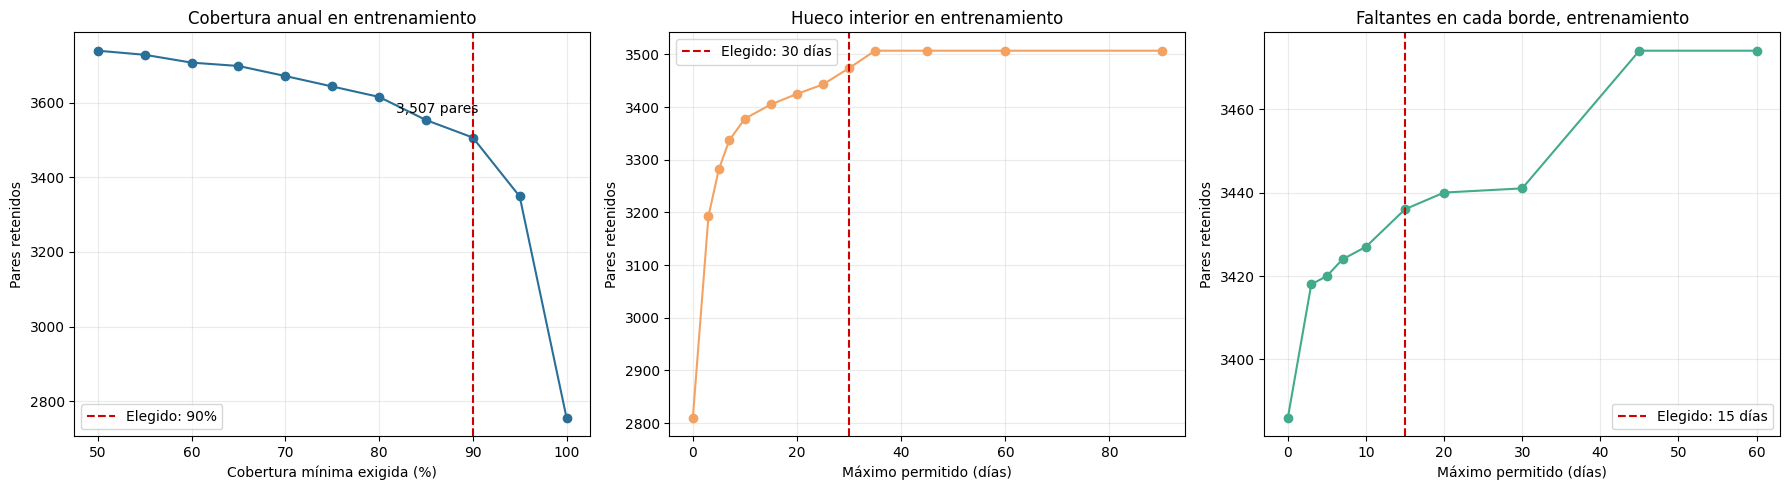

In [13]:
def longitud_maxima_racha(serie_booleana):
    # Longitud máxima de una racha True; cero cuando no existen True.
    valores = np.asarray(serie_booleana, dtype=bool)
    if not valores.any():
        return 0
    cambios = np.diff(np.r_[False, valores, False].astype(np.int8))
    inicios = np.flatnonzero(cambios == 1)
    finales = np.flatnonzero(cambios == -1)
    return int((finales - inicios).max())


fechas_validas_por_par = (
    datos_trabajo.loc[
        datos_trabajo.station_id.notna()
        & datos_trabajo.fecha.notna()
        & datos_trabajo.precipitacion_limpia_mm.notna(),
        ['station_id', 'year', 'fecha']
    ]
    .drop_duplicates()
    .groupby(['station_id', 'year'])['fecha']
    .agg(set)
)

diagnosticos = []
for par in pares_trabajo.itertuples(index=False):
    estacion = par.station_id
    anio = int(par.year)
    calendario = pd.date_range(f'{anio}-01-01', f'{anio}-12-31', freq='D')
    fechas_validas = fechas_validas_por_par.get((estacion, anio), set())
    observado = calendario.isin(fechas_validas)
    posiciones_validas = np.flatnonzero(observado)

    if len(posiciones_validas) == 0:
        faltantes_inicio = len(calendario)
        faltantes_final = len(calendario)
        hueco_interior_max = len(calendario)
    else:
        primera = int(posiciones_validas[0])
        ultima = int(posiciones_validas[-1])
        faltantes_inicio = primera
        faltantes_final = len(calendario) - 1 - ultima
        hueco_interior_max = longitud_maxima_racha(~observado[primera:ultima + 1])

    dias_validos = int(observado.sum())
    dias_esperados = len(calendario)
    diagnosticos.append({
        'station_id': estacion,
        'year': anio,
        'particion': par.particion,
        'dias_validos': dias_validos,
        'dias_esperados': dias_esperados,
        'cobertura_anual': dias_validos / dias_esperados,
        'faltantes_inicio': faltantes_inicio,
        'faltantes_final': faltantes_final,
        'hueco_interior_max': hueco_interior_max,
    })

diagnostico_continuidad = pd.DataFrame(diagnosticos)
diagnostico_entrenamiento = diagnostico_continuidad.loc[
    diagnostico_continuidad.particion.eq('ENTRENAMIENTO')
].copy()

display(Markdown('**Distribución usada para decidir: únicamente entrenamiento 1981–1995:**'))
display(
    diagnostico_entrenamiento[
        ['cobertura_anual', 'hueco_interior_max', 'faltantes_inicio', 'faltantes_final']
    ].describe(percentiles=[.50, .75, .80, .85, .90, .95, .975, .99]).T
)

# La cobertura se evalúa cada cinco puntos porcentuales. Validación y prueba
# no intervienen en esta tabla ni en las gráficas de elección.
sensibilidad_anual = []
for umbral in np.arange(0.50, 1.001, 0.05):
    seleccion = diagnostico_entrenamiento.cobertura_anual.ge(umbral - 1e-12)
    sensibilidad_anual.append({
        'umbral_pct': int(round(100 * umbral)),
        'pares_retenidos_entrenamiento': int(seleccion.sum()),
        'estaciones_retenidas_entrenamiento': int(diagnostico_entrenamiento.loc[seleccion, 'station_id'].nunique()),
        'pares_retenidos_pct': 100 * seleccion.mean(),
        'seleccionado': bool(np.isclose(umbral, .90)),
    })
sensibilidad_anual = pd.DataFrame(sensibilidad_anual)
sensibilidad_anual['pares_perdidos_vs_umbral_anterior'] = (
    sensibilidad_anual.pares_retenidos_entrenamiento.shift(1)
    - sensibilidad_anual.pares_retenidos_entrenamiento
).fillna(0).astype(int)
sensibilidad_anual['estaciones_perdidas_vs_umbral_anterior'] = (
    sensibilidad_anual.estaciones_retenidas_entrenamiento.shift(1)
    - sensibilidad_anual.estaciones_retenidas_entrenamiento
).fillna(0).astype(int)
sensibilidad_anual['pares_excluidos_acumulados'] = (
    len(diagnostico_entrenamiento) - sensibilidad_anual.pares_retenidos_entrenamiento
)

base_anual_90_entrenamiento = diagnostico_entrenamiento.cobertura_anual.ge(0.90)
sensibilidad_interior = []
for limite in [0, 3, 5, 7, 10, 15, 20, 25, 30, 35, 45, 60, 90]:
    seleccion = base_anual_90_entrenamiento & diagnostico_entrenamiento.hueco_interior_max.le(limite)
    sensibilidad_interior.append({
        'limite_dias': limite,
        'pares_retenidos_entrenamiento': int(seleccion.sum()),
        'estaciones_retenidas_entrenamiento': int(diagnostico_entrenamiento.loc[seleccion, 'station_id'].nunique()),
        'porcentaje_de_base_90': 100 * seleccion.sum() / base_anual_90_entrenamiento.sum(),
        'seleccionado': limite == 30,
    })
sensibilidad_interior = pd.DataFrame(sensibilidad_interior)
sensibilidad_interior['pares_recuperados_vs_limite_anterior'] = (
    sensibilidad_interior.pares_retenidos_entrenamiento.diff().fillna(0).astype(int)
)
sensibilidad_interior['pares_excluidos_por_hueco'] = (
    base_anual_90_entrenamiento.sum() - sensibilidad_interior.pares_retenidos_entrenamiento
)

base_anual_interior_entrenamiento = (
    base_anual_90_entrenamiento & diagnostico_entrenamiento.hueco_interior_max.le(30)
)
maximo_borde_entrenamiento = diagnostico_entrenamiento[['faltantes_inicio', 'faltantes_final']].max(axis=1)
sensibilidad_bordes = []
for limite in [0, 3, 5, 7, 10, 15, 20, 30, 45, 60]:
    seleccion = base_anual_interior_entrenamiento & maximo_borde_entrenamiento.le(limite)
    sensibilidad_bordes.append({
        'limite_dias_por_borde': limite,
        'pares_retenidos_entrenamiento': int(seleccion.sum()),
        'estaciones_retenidas_entrenamiento': int(diagnostico_entrenamiento.loc[seleccion, 'station_id'].nunique()),
        'porcentaje_de_base_previa': 100 * seleccion.sum() / base_anual_interior_entrenamiento.sum(),
        'seleccionado': limite == 15,
    })
sensibilidad_bordes = pd.DataFrame(sensibilidad_bordes)
sensibilidad_bordes['pares_recuperados_vs_limite_anterior'] = (
    sensibilidad_bordes.pares_retenidos_entrenamiento.diff().fillna(0).astype(int)
)
sensibilidad_bordes['pares_excluidos_por_borde'] = (
    base_anual_interior_entrenamiento.sum() - sensibilidad_bordes.pares_retenidos_entrenamiento
)


def resaltar_seleccion(fila):
    color = 'background-color: #d9ead3; font-weight: bold' if bool(fila['seleccionado']) else ''
    return [color] * len(fila)


display(Markdown('**Cobertura anual en entrenamiento: costo marginal de exigir cinco puntos adicionales:**'))
display(
    sensibilidad_anual.style.apply(resaltar_seleccion, axis=1)
    .format({'pares_retenidos_pct': '{:.1f}%'})
)
display(Markdown('**Hueco interior en entrenamiento: ganancia al permitir más días consecutivos faltantes:**'))
display(
    sensibilidad_interior.style.apply(resaltar_seleccion, axis=1)
    .format({'porcentaje_de_base_90': '{:.1f}%'})
)
display(Markdown('**Bordes en entrenamiento: ganancia al permitir más días sin soporte:**'))
display(
    sensibilidad_bordes.style.apply(resaltar_seleccion, axis=1)
    .format({'porcentaje_de_base_previa': '{:.1f}%'})
)

fila_85 = sensibilidad_anual.loc[sensibilidad_anual.umbral_pct.eq(85)].iloc[0]
fila_90 = sensibilidad_anual.loc[sensibilidad_anual.umbral_pct.eq(90)].iloc[0]
fila_95 = sensibilidad_anual.loc[sensibilidad_anual.umbral_pct.eq(95)].iloc[0]
perdida_85_90 = int(fila_85.pares_retenidos_entrenamiento - fila_90.pares_retenidos_entrenamiento)
perdida_90_95 = int(fila_90.pares_retenidos_entrenamiento - fila_95.pares_retenidos_entrenamiento)

interior_15 = int(sensibilidad_interior.loc[sensibilidad_interior.limite_dias.eq(15), 'pares_retenidos_entrenamiento'].iloc[0])
interior_30 = int(sensibilidad_interior.loc[sensibilidad_interior.limite_dias.eq(30), 'pares_retenidos_entrenamiento'].iloc[0])
borde_15 = int(sensibilidad_bordes.loc[sensibilidad_bordes.limite_dias_por_borde.eq(15), 'pares_retenidos_entrenamiento'].iloc[0])
borde_30 = int(sensibilidad_bordes.loc[sensibilidad_bordes.limite_dias_por_borde.eq(30), 'pares_retenidos_entrenamiento'].iloc[0])
p95_hueco = diagnostico_entrenamiento.hueco_interior_max.quantile(.95)
p975_hueco = diagnostico_entrenamiento.hueco_interior_max.quantile(.975)

evidencia_umbral = pd.DataFrame([
    {
        'decision': 'Cobertura anual 90%',
        'evidencia_entrenamiento': f'85→90 pierde {perdida_85_90} pares; 90→95 pierde {perdida_90_95}',
        'criterio': 'Punto previo al aumento del costo marginal',
    },
    {
        'decision': 'Hueco interior 30 días',
        'evidencia_entrenamiento': f'P95={p95_hueco:.1f}; P97,5={p975_hueco:.1f}; recupera {interior_30-interior_15} pares frente a 15 días',
        'criterio': 'Separa la cola extrema y conserva casos revisables',
    },
    {
        'decision': 'Cada borde 15 días',
        'evidencia_entrenamiento': f'Pasar de 15 a 30 solo recupera {borde_30-borde_15} pares',
        'criterio': 'Limita extrapolación con bajo costo muestral',
    },
])
display(Markdown('**Resumen determinístico de la elección, sin información de validación o prueba:**'))
display(evidencia_umbral)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(sensibilidad_anual.umbral_pct, sensibilidad_anual.pares_retenidos_entrenamiento, marker='o', color='#2a6f97')
axes[0].axvline(90, color='#d00000', linestyle='--', label='Elegido: 90%')
axes[0].annotate(f"{int(fila_90.pares_retenidos_entrenamiento):,} pares", (90, fila_90.pares_retenidos_entrenamiento), xytext=(-55, 18), textcoords='offset points')
axes[0].set(title='Cobertura anual en entrenamiento', xlabel='Cobertura mínima exigida (%)', ylabel='Pares retenidos')
axes[0].legend()
axes[0].grid(alpha=.25)

axes[1].plot(sensibilidad_interior.limite_dias, sensibilidad_interior.pares_retenidos_entrenamiento, marker='o', color='#f4a261')
axes[1].axvline(30, color='#d00000', linestyle='--', label='Elegido: 30 días')
axes[1].set(title='Hueco interior en entrenamiento', xlabel='Máximo permitido (días)', ylabel='Pares retenidos')
axes[1].legend()
axes[1].grid(alpha=.25)

axes[2].plot(sensibilidad_bordes.limite_dias_por_borde, sensibilidad_bordes.pares_retenidos_entrenamiento, marker='o', color='#43aa8b')
axes[2].axvline(15, color='#d00000', linestyle='--', label='Elegido: 15 días')
axes[2].set(title='Faltantes en cada borde, entrenamiento', xlabel='Máximo permitido (días)', ylabel='Pares retenidos')
axes[2].legend()
axes[2].grid(alpha=.25)

plt.tight_layout()
GRAPH_DIR = ROOT / 'graficas_estaciones'
GRAPH_DIR.mkdir(exist_ok=True)
fig.savefig(GRAPH_DIR / 'justificacion_cobertura_continuidad.png', dpi=160, bbox_inches='tight')
plt.show()


## Justificación de los umbrales sin fuga de información

Las filas verdes identifican las decisiones aplicadas. Todas las pérdidas, ganancias, percentiles y gráficas anteriores se calculan con **1981–1995**.

### Cobertura anual de 90%

Un año normal con 90% de cobertura admite como máximo 36 días faltantes y uno bisiesto 37. La tabla compara el costo marginal de aumentar la cobertura en intervalos de cinco puntos. Se selecciona el punto anterior a la pérdida más marcada, sin exigir años perfectos.

### Hueco interior de 30 días

El límite se contrasta con los percentiles de la longitud máxima de hueco en entrenamiento. Los pares con huecos de 16 a 30 días se conservan con `revision_hueco_16_30`, porque tienen observaciones a ambos lados pero mayor incertidumbre.

### Quince días en cada borde

En los extremos no existen observaciones del mismo año a ambos lados. Por eso el borde se limita a la mitad del hueco interior y se compara cuánto se recuperaría al permitir 30 días. Si la ganancia es pequeña, se prefiere reducir la extrapolación.

### Aplicación posterior

Los valores 90, 30 y 15 quedan congelados después de esta sección. Los conteos de validación y prueba se calculan después, pero nunca se usan para modificar estas decisiones.


In [14]:
UMBRAL_ANUAL = 0.90
HUECO_INTERIOR_MAX_DIAS = 30
BORDE_MAX_DIAS = 15

diagnostico_continuidad['cumple_anual_90'] = diagnostico_continuidad.cobertura_anual.ge(UMBRAL_ANUAL)
diagnostico_continuidad['cumple_hueco_interior_30'] = diagnostico_continuidad.hueco_interior_max.le(HUECO_INTERIOR_MAX_DIAS)
diagnostico_continuidad['cumple_borde_inicio_15'] = diagnostico_continuidad.faltantes_inicio.le(BORDE_MAX_DIAS)
diagnostico_continuidad['cumple_borde_final_15'] = diagnostico_continuidad.faltantes_final.le(BORDE_MAX_DIAS)
diagnostico_continuidad['cumple_regla_continuidad'] = (
    diagnostico_continuidad.cumple_anual_90
    & diagnostico_continuidad.cumple_hueco_interior_30
    & diagnostico_continuidad.cumple_borde_inicio_15
    & diagnostico_continuidad.cumple_borde_final_15
)
diagnostico_continuidad['revision_hueco_16_30'] = (
    diagnostico_continuidad.cumple_regla_continuidad
    & diagnostico_continuidad.hueco_interior_max.between(16, 30, inclusive='both')
)

condiciones = [
    ~diagnostico_continuidad.cumple_anual_90,
    diagnostico_continuidad.cumple_anual_90 & ~diagnostico_continuidad.cumple_hueco_interior_30,
    diagnostico_continuidad.cumple_anual_90
        & diagnostico_continuidad.cumple_hueco_interior_30
        & ~(diagnostico_continuidad.cumple_borde_inicio_15 & diagnostico_continuidad.cumple_borde_final_15),
    diagnostico_continuidad.revision_hueco_16_30,
]
estados = [
    'INSUFICIENTE_COBERTURA_ANUAL',
    'INSUFICIENTE_HUECO_INTERIOR',
    'INSUFICIENTE_BORDE',
    'ELEGIBLE_REVISAR_HUECO',
]
diagnostico_continuidad['estado_continuidad'] = np.select(condiciones, estados, default='ELEGIBLE')

pasos_continuidad = [
    ('00 pares iniciales de la partición', pd.Series(True, index=diagnostico_continuidad.index)),
    ('01 cobertura anual >= 90%', diagnostico_continuidad.cumple_anual_90),
    ('02 hueco interior <= 30 días', diagnostico_continuidad.cumple_anual_90 & diagnostico_continuidad.cumple_hueco_interior_30),
    ('03 cada borde <= 15 días', diagnostico_continuidad.cumple_regla_continuidad),
]

filas_traza = []
for particion in ORDEN_PARTICIONES + ['TOTAL']:
    mascara_particion = (
        pd.Series(True, index=diagnostico_continuidad.index)
        if particion == 'TOTAL'
        else diagnostico_continuidad.particion.eq(particion)
    )
    pares_iniciales = int(mascara_particion.sum())
    pares_previos = None
    estaciones_previas = None
    for paso, mascara_regla in pasos_continuidad:
        mascara = mascara_particion & mascara_regla
        pares = int(mascara.sum())
        estaciones = int(diagnostico_continuidad.loc[mascara, 'station_id'].nunique())
        filas_traza.append({
            'particion': particion,
            'paso': paso,
            'pares_estacion_anio': pares,
            'estaciones': estaciones,
            'pares_excluidos_en_paso': 0 if pares_previos is None else pares_previos - pares,
            'estaciones_excluidas_en_paso': 0 if estaciones_previas is None else estaciones_previas - estaciones,
            'pares_retenidos_desde_inicio_pct': 100 * pares / pares_iniciales,
        })
        pares_previos = pares
        estaciones_previas = estaciones
trazabilidad_continuidad = pd.DataFrame(filas_traza)

display(Markdown('**Aplicación de las reglas congeladas, reportada por partición:**'))
display(
    trazabilidad_continuidad.style
    .format({'pares_retenidos_desde_inicio_pct': '{:.1f}%'})
    .background_gradient(subset=['pares_excluidos_en_paso'], cmap='Reds')
)

resumen_estados_particion = pd.crosstab(
    diagnostico_continuidad.estado_continuidad,
    diagnostico_continuidad.particion,
).reindex(columns=ORDEN_PARTICIONES, fill_value=0)
resumen_estados_particion['TOTAL'] = resumen_estados_particion.sum(axis=1)
display(Markdown('**Motivo de clasificación de los pares por partición:**'))
display(resumen_estados_particion)

resultado_reglas_por_particion = (
    trazabilidad_continuidad.loc[
        trazabilidad_continuidad.paso.eq('03 cada borde <= 15 días')
        & trazabilidad_continuidad.particion.ne('TOTAL'),
        ['particion', 'pares_estacion_anio', 'estaciones', 'pares_retenidos_desde_inicio_pct']
    ]
    .reset_index(drop=True)
)
display(Markdown('**Resultado provisional después de cobertura y continuidad:**'))
display(resultado_reglas_por_particion.style.format({'pares_retenidos_desde_inicio_pct': '{:.1f}%'}))
display(Markdown(
    '**Lectura:** las diferencias entre particiones se reportan, pero no cambian los umbrales definidos con entrenamiento. '
    'La clasificación se recalculará después de decidir totales mensuales, ceros falsos y otras anomalías.'
))


**Aplicación de las reglas congeladas, reportada por partición:**

,particion,paso,pares_estacion_anio,estaciones,pares_excluidos_en_paso,estaciones_excluidas_en_paso,pares_retenidos_desde_inicio_pct
0,ENTRENAMIENTO,00 pares iniciales de la partición,3847,318,0,0,100.0%
1,ENTRENAMIENTO,01 cobertura anual >= 90%,3507,304,340,14,91.2%
2,ENTRENAMIENTO,02 hueco interior <= 30 días,3474,303,33,1,90.3%
3,ENTRENAMIENTO,03 cada borde <= 15 días,3436,302,38,1,89.3%
4,VALIDACION,00 pares iniciales de la partición,1098,241,0,0,100.0%
5,VALIDACION,01 cobertura anual >= 90%,1001,222,97,19,91.2%
6,VALIDACION,02 hueco interior <= 30 días,996,222,5,0,90.7%
7,VALIDACION,03 cada borde <= 15 días,987,221,9,1,89.9%
8,PRUEBA,00 pares iniciales de la partición,569,194,0,0,100.0%
9,PRUEBA,01 cobertura anual >= 90%,524,189,45,5,92.1%


**Motivo de clasificación de los pares por partición:**

particion,ENTRENAMIENTO,VALIDACION,PRUEBA,TOTAL
estado_continuidad,,,,
ELEGIBLE,3367,965,501,4833
ELEGIBLE_REVISAR_HUECO,69,22,7,98
INSUFICIENTE_BORDE,38,9,9,56
INSUFICIENTE_COBERTURA_ANUAL,340,97,45,482
INSUFICIENTE_HUECO_INTERIOR,33,5,7,45


**Resultado provisional después de cobertura y continuidad:**

,particion,pares_estacion_anio,estaciones,pares_retenidos_desde_inicio_pct
0,ENTRENAMIENTO,3436,302,89.3%
1,VALIDACION,987,221,89.9%
2,PRUEBA,508,187,89.3%


**Lectura:** las diferencias entre particiones se reportan, pero no cambian los umbrales definidos con entrenamiento. La clasificación se recalculará después de decidir totales mensuales, ceros falsos y otras anomalías.

# Decisión 6: mínimo de cinco años válidos en entrenamiento

Para las estaciones usadas en el desarrollo del modelo se exigen al menos **cinco pares estación–año válidos dentro de entrenamiento (1981–1995)**, después de cobertura y continuidad.

Los años no tienen que ser consecutivos. Validación y prueba no ayudan a una estación a alcanzar el mínimo. La lista de estaciones elegibles se congela con entrenamiento y luego se aplica a los otros periodos.

No se eliminan físicamente las observaciones: se crean `anios_validos_entrenamiento`, `cumple_minimo_5_anios_entrenamiento` y el motivo de exclusión. Cuando el docente entregue las estaciones reservadas, estas se identificarán aparte y no se usarán para estimar este criterio ni para ajustar el modelo.


**Sensibilidad calculada únicamente con años de entrenamiento:**

,minimo_anios_validos_entrenamiento,estaciones_retenidas_entrenamiento,pares_retenidos_entrenamiento,porcentaje_estaciones_entrenamiento,porcentaje_pares_entrenamiento,seleccionado,estaciones_perdidas_vs_minimo_anterior,pares_perdidos_vs_minimo_anterior
0,1,302,3436,100.0%,100.0%,False,0,0
1,2,281,3415,93.0%,99.4%,False,21,21
2,3,273,3399,90.4%,98.9%,False,8,16
3,4,264,3372,87.4%,98.1%,False,9,27
4,5,263,3368,87.1%,98.0%,True,1,4
5,6,256,3333,84.8%,97.0%,False,7,35
7,8,250,3296,82.8%,95.9%,False,1,7
9,10,232,3142,76.8%,91.4%,False,10,90
11,12,197,2776,65.2%,80.8%,False,16,176
14,15,95,1425,31.5%,41.5%,False,46,644


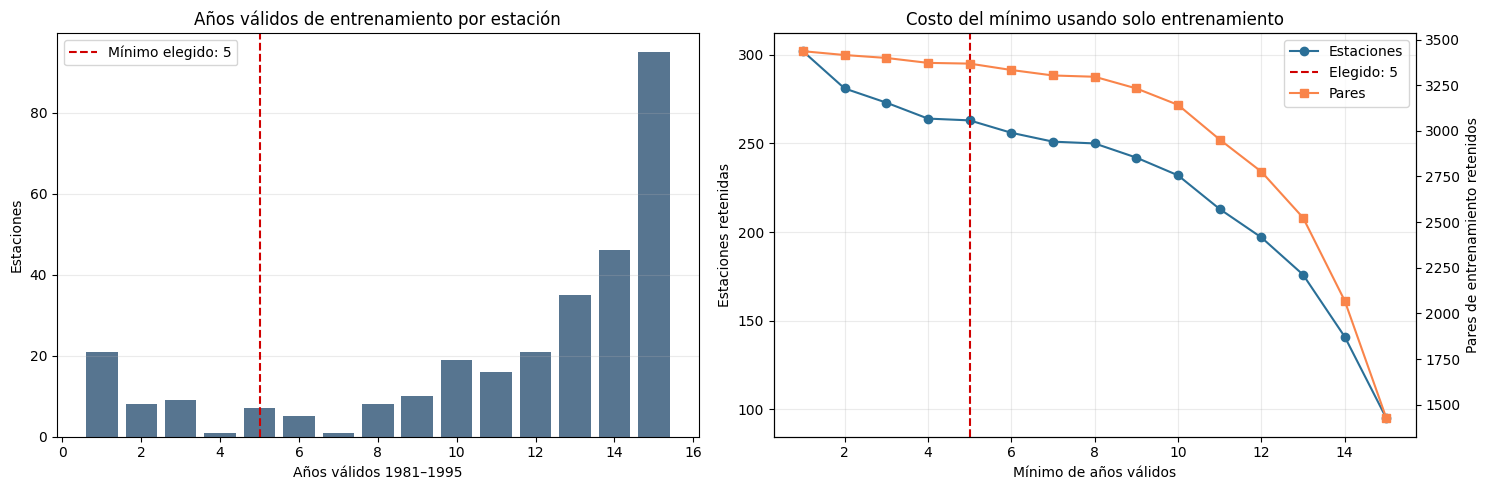

**Aplicación de la lista de estaciones elegibles a cada partición:**

,particion,pares_antes,pares_despues,pares_excluidos,estaciones_antes,estaciones_despues,estaciones_excluidas,pares_retenidos_pct
0,ENTRENAMIENTO,3436,3368,68,302,263,39,98.0%
1,VALIDACION,987,923,64,221,205,16,93.5%
2,PRUEBA,508,478,30,187,173,14,94.1%
3,TOTAL,4931,4769,162,309,263,46,96.7%


**Lectura:** pasar de cuatro a cinco años válidos de entrenamiento aparta 1 estación y 4 pares de entrenamiento. El criterio conserva **263 estaciones de desarrollo**. La lista de estaciones reservadas del docente sigue pendiente y se manejará como un conjunto separado.

In [15]:
MINIMO_ANIOS_VALIDOS = 5

pares_validos_antes_minimo = diagnostico_continuidad.loc[
    diagnostico_continuidad.cumple_regla_continuidad,
    ['station_id', 'year', 'particion']
].drop_duplicates()

pares_validos_entrenamiento = pares_validos_antes_minimo.loc[
    pares_validos_antes_minimo.particion.eq('ENTRENAMIENTO')
].copy()

anios_validos_entrenamiento_por_estacion = (
    pares_validos_entrenamiento.groupby('station_id', as_index=False)
    .agg(
        anios_validos_entrenamiento=('year', 'nunique'),
        primer_anio_valido_entrenamiento=('year', 'min'),
        ultimo_anio_valido_entrenamiento=('year', 'max'),
    )
)

sensibilidad_minimo_anios = []
maximo_anios_observado = int(anios_validos_entrenamiento_por_estacion.anios_validos_entrenamiento.max())
for minimo in range(1, maximo_anios_observado + 1):
    estaciones_seleccionadas = anios_validos_entrenamiento_por_estacion.loc[
        anios_validos_entrenamiento_por_estacion.anios_validos_entrenamiento.ge(minimo), 'station_id'
    ]
    mascara_pares = pares_validos_entrenamiento.station_id.isin(estaciones_seleccionadas)
    sensibilidad_minimo_anios.append({
        'minimo_anios_validos_entrenamiento': minimo,
        'estaciones_retenidas_entrenamiento': int(len(estaciones_seleccionadas)),
        'pares_retenidos_entrenamiento': int(mascara_pares.sum()),
        'porcentaje_estaciones_entrenamiento': 100 * len(estaciones_seleccionadas) / len(anios_validos_entrenamiento_por_estacion),
        'porcentaje_pares_entrenamiento': 100 * mascara_pares.mean(),
        'seleccionado': minimo == MINIMO_ANIOS_VALIDOS,
    })
sensibilidad_minimo_anios = pd.DataFrame(sensibilidad_minimo_anios)
sensibilidad_minimo_anios['estaciones_perdidas_vs_minimo_anterior'] = (
    sensibilidad_minimo_anios.estaciones_retenidas_entrenamiento.shift(1)
    - sensibilidad_minimo_anios.estaciones_retenidas_entrenamiento
).fillna(0).astype(int)
sensibilidad_minimo_anios['pares_perdidos_vs_minimo_anterior'] = (
    sensibilidad_minimo_anios.pares_retenidos_entrenamiento.shift(1)
    - sensibilidad_minimo_anios.pares_retenidos_entrenamiento
).fillna(0).astype(int)

estaciones_con_minimo_5 = anios_validos_entrenamiento_por_estacion.loc[
    anios_validos_entrenamiento_por_estacion.anios_validos_entrenamiento.ge(MINIMO_ANIOS_VALIDOS),
    'station_id'
]
pares_validos_minimo_5 = pares_validos_antes_minimo.loc[
    pares_validos_antes_minimo.station_id.isin(estaciones_con_minimo_5)
].copy()

diagnostico_continuidad = diagnostico_continuidad.merge(
    anios_validos_entrenamiento_por_estacion[['station_id', 'anios_validos_entrenamiento']],
    on='station_id', how='left'
)
diagnostico_continuidad['anios_validos_entrenamiento'] = (
    diagnostico_continuidad.anios_validos_entrenamiento.fillna(0).astype(int)
)
diagnostico_continuidad['cumple_minimo_5_anios_entrenamiento'] = (
    diagnostico_continuidad.anios_validos_entrenamiento.ge(MINIMO_ANIOS_VALIDOS)
)
diagnostico_continuidad['motivo_exclusion_minimo_anios'] = np.where(
    diagnostico_continuidad.cumple_minimo_5_anios_entrenamiento,
    '',
    'MENOS_DE_5_ANIOS_VALIDOS_EN_ENTRENAMIENTO'
)

filas_traza_minimo = []
for particion in ORDEN_PARTICIONES + ['TOTAL']:
    antes = (
        pares_validos_antes_minimo
        if particion == 'TOTAL'
        else pares_validos_antes_minimo.loc[pares_validos_antes_minimo.particion.eq(particion)]
    )
    despues = (
        pares_validos_minimo_5
        if particion == 'TOTAL'
        else pares_validos_minimo_5.loc[pares_validos_minimo_5.particion.eq(particion)]
    )
    filas_traza_minimo.append({
        'particion': particion,
        'pares_antes': int(len(antes)),
        'pares_despues': int(len(despues)),
        'pares_excluidos': int(len(antes) - len(despues)),
        'estaciones_antes': int(antes.station_id.nunique()),
        'estaciones_despues': int(despues.station_id.nunique()),
        'estaciones_excluidas': int(antes.station_id.nunique() - despues.station_id.nunique()),
        'pares_retenidos_pct': 100 * len(despues) / len(antes) if len(antes) else np.nan,
    })
trazabilidad_minimo_anios = pd.DataFrame(filas_traza_minimo)

filas_mostradas = sorted(set(
    x for x in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, maximo_anios_observado]
    if x <= maximo_anios_observado
))
tabla_minimo = sensibilidad_minimo_anios.loc[
    sensibilidad_minimo_anios.minimo_anios_validos_entrenamiento.isin(filas_mostradas)
].copy()

display(Markdown('**Sensibilidad calculada únicamente con años de entrenamiento:**'))
display(
    tabla_minimo.style.apply(resaltar_seleccion, axis=1)
    .format({
        'porcentaje_estaciones_entrenamiento': '{:.1f}%',
        'porcentaje_pares_entrenamiento': '{:.1f}%'
    })
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
conteos_anios = anios_validos_entrenamiento_por_estacion.anios_validos_entrenamiento.value_counts().sort_index()
axes[0].bar(conteos_anios.index, conteos_anios.values, color='#577590')
axes[0].axvline(5, color='#d00000', linestyle='--', label='Mínimo elegido: 5')
axes[0].set(title='Años válidos de entrenamiento por estación', xlabel='Años válidos 1981–1995', ylabel='Estaciones')
axes[0].legend()
axes[0].grid(axis='y', alpha=.25)

axes[1].plot(
    sensibilidad_minimo_anios.minimo_anios_validos_entrenamiento,
    sensibilidad_minimo_anios.estaciones_retenidas_entrenamiento,
    marker='o', label='Estaciones', color='#2a6f97'
)
ax_pares = axes[1].twinx()
ax_pares.plot(
    sensibilidad_minimo_anios.minimo_anios_validos_entrenamiento,
    sensibilidad_minimo_anios.pares_retenidos_entrenamiento,
    marker='s', label='Pares', color='#f9844a'
)
axes[1].axvline(5, color='#d00000', linestyle='--', label='Elegido: 5')
axes[1].set(title='Costo del mínimo usando solo entrenamiento', xlabel='Mínimo de años válidos', ylabel='Estaciones retenidas')
ax_pares.set_ylabel('Pares de entrenamiento retenidos')
lineas_1, etiquetas_1 = axes[1].get_legend_handles_labels()
lineas_2, etiquetas_2 = ax_pares.get_legend_handles_labels()
axes[1].legend(lineas_1 + lineas_2, etiquetas_1 + etiquetas_2, loc='upper right')
axes[1].grid(alpha=.25)
plt.tight_layout()
fig.savefig(GRAPH_DIR / 'justificacion_minimo_anios.png', dpi=160, bbox_inches='tight')
plt.show()

display(Markdown('**Aplicación de la lista de estaciones elegibles a cada partición:**'))
display(trazabilidad_minimo_anios.style.format({'pares_retenidos_pct': '{:.1f}%'}))
fila_4 = sensibilidad_minimo_anios.loc[
    sensibilidad_minimo_anios.minimo_anios_validos_entrenamiento.eq(4)
].iloc[0]
fila_5 = sensibilidad_minimo_anios.loc[
    sensibilidad_minimo_anios.minimo_anios_validos_entrenamiento.eq(5)
].iloc[0]
estaciones_perdidas_4_5 = int(fila_5.estaciones_perdidas_vs_minimo_anterior)
palabra_estacion = 'estación' if estaciones_perdidas_4_5 == 1 else 'estaciones'
display(Markdown(
    f"**Lectura:** pasar de cuatro a cinco años válidos de entrenamiento aparta "
    f"{estaciones_perdidas_4_5:,} {palabra_estacion} y "
    f"{int(fila_5.pares_perdidos_vs_minimo_anterior):,} pares de entrenamiento. "
    f"El criterio conserva **{len(estaciones_con_minimo_5):,} estaciones de desarrollo**. "
    "La lista de estaciones reservadas del docente sigue pendiente y se manejará como un conjunto separado."
))


# Resultado final del preprocesamiento terrestre

El resultado conserva los valores originales, documenta cada invalidación y aplica en este orden: errores confirmados, reglas adaptadas de Jacobo, cobertura/continuidad y mínimo de años de entrenamiento. No se imputa precipitación en esta fase.


In [ ]:
resumen_final = (
    pares_validos_minimo_5.groupby('particion', observed=True)
    .agg(
        estaciones=('station_id', 'nunique'),
        pares_estacion_anio=('year', 'size'),
    )
    .reindex(ORDEN_PARTICIONES)
    .reset_index()
)
resumen_final.loc[len(resumen_final)] = [
    'TOTAL', pares_validos_minimo_5.station_id.nunique(), len(pares_validos_minimo_5)
]
display(Markdown('**Pares elegibles después de todas las decisiones:**'))
display(resumen_final)
display(Markdown(
    '**Salida metodológica:** `datos_trabajo` mantiene la precipitación original, la precipitación limpia y '
    'una bandera por motivo; `pares_validos_minimo_5` identifica las curvas que pueden avanzar a FDA. '
    'La prueba no se usó para seleccionar ninguna regla.'
))
